########################################################################
# CG — Relay + Base Case + Benchmark + Plots
########################################################################

######################################################################
# RELAY NETWORK
######################################################################

=== Network (RELAY) ===  |F|=5  |D|=40  |I|=15  T=192
  loc_in:    741  loc_out:   7876  rel_L:  23112  rel_E:  26944
  direct:     52  trans:   2865  dead_DR:   1961  dead_RO:    732
  access:  37948  egress:  55638  wait_d:   2880
  A^C=34646  A^pos=29647  home-bases=40
Set parameter Username
Set parameter LicenseID to value 2819104
Academic license - for non-commercial use only - expires 2027-05-06

=== Building pricing cache ===
  cache build: 0.8s  (bases=40, FW relays=15, composite arcs=23112)

=== Warm-start ===
  Driver-aware construction: 5/5 shipments with matched duties, 11 drivers reserved
  Direct:3F  Relay:15F  Seed:0F  Matched

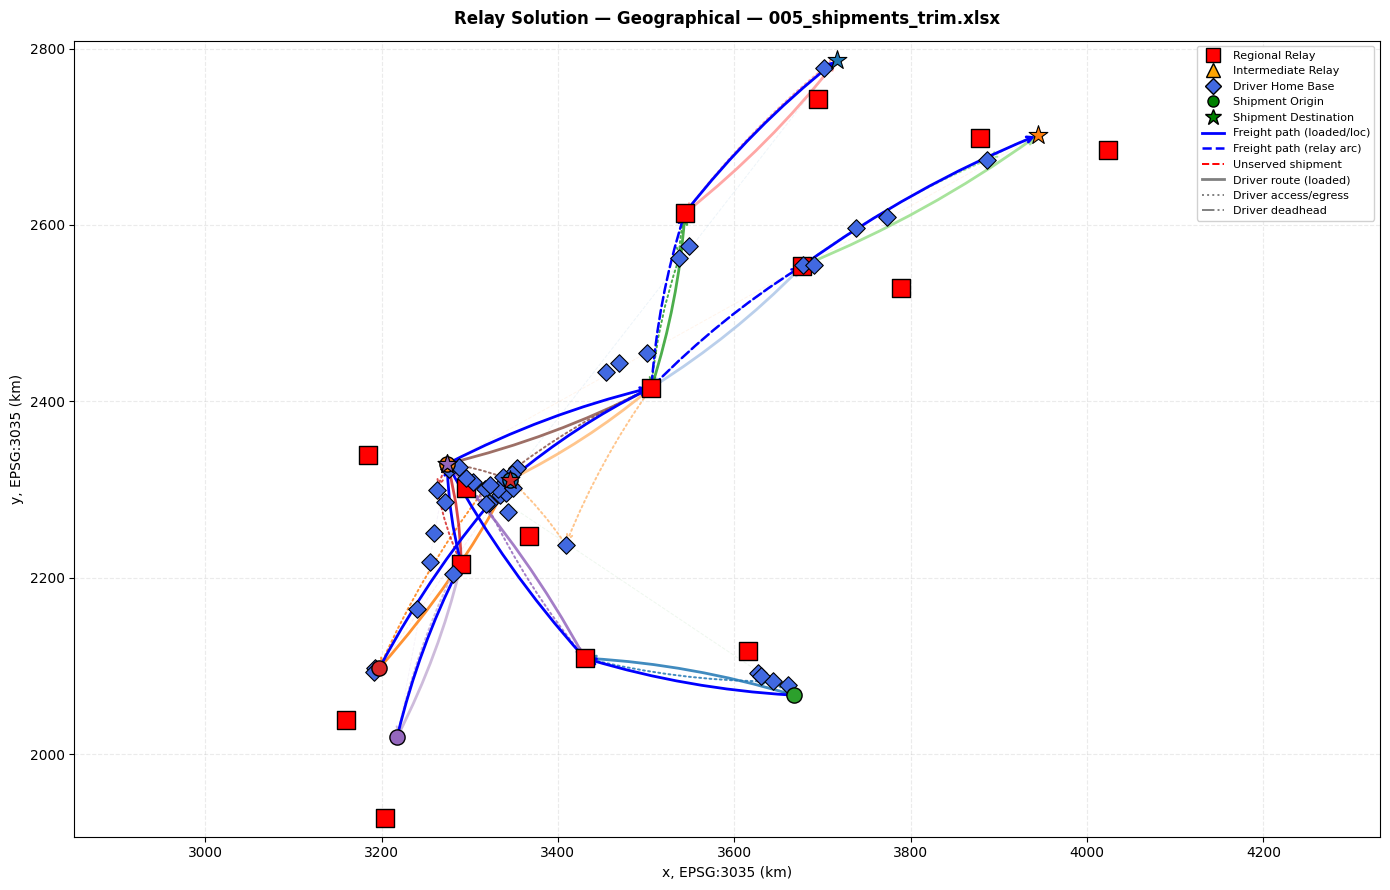

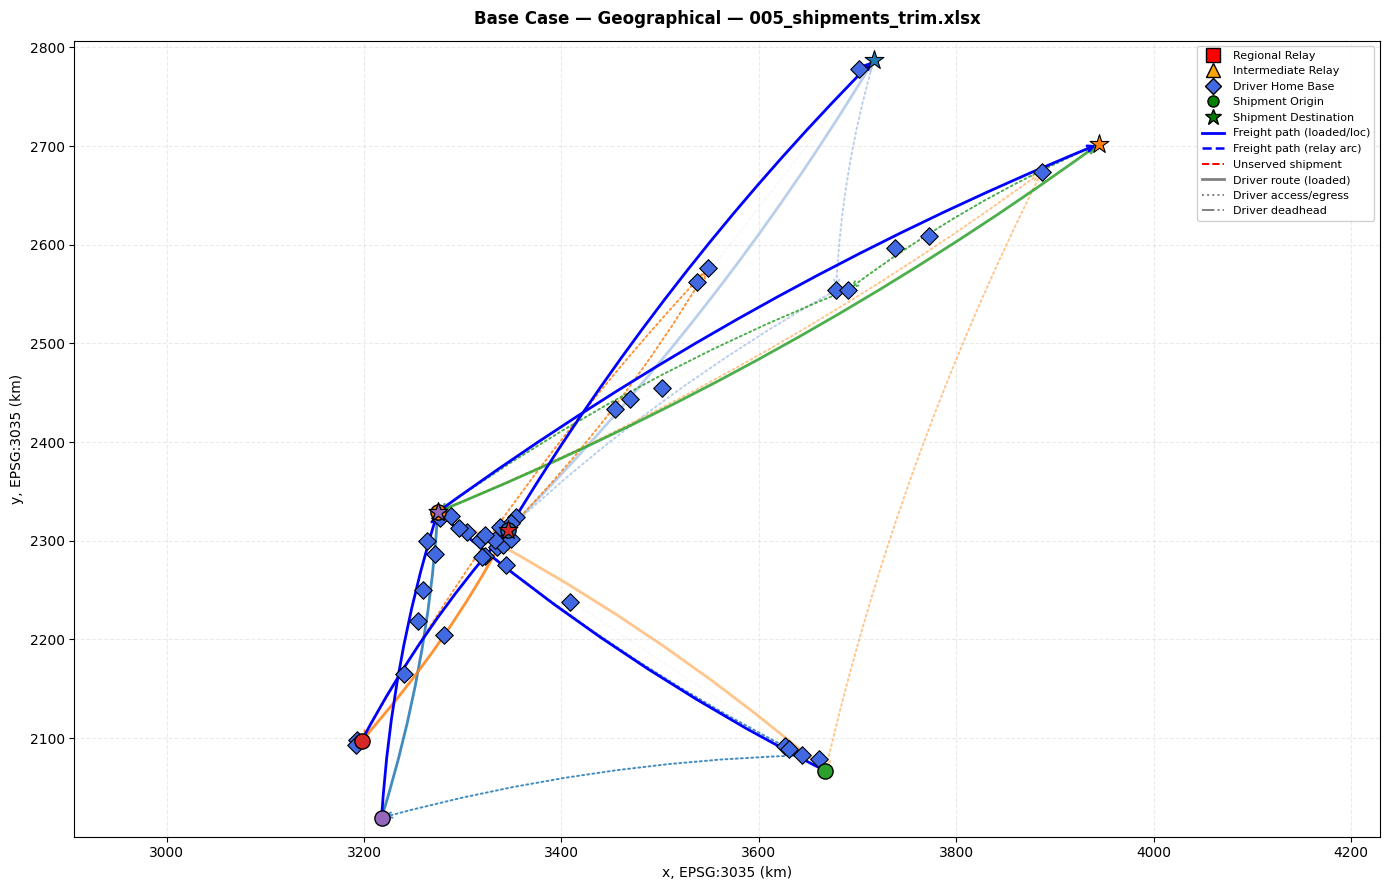

In [ ]:
from __future__ import annotations

import heapq, math, time, random, itertools
from collections import defaultdict
from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional, Set, Tuple

import gurobipy as gp
import numpy as np
import pandas as pd
from gurobipy import GRB, Model
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

Arc  = Tuple[str, str, int, int]
Node = Tuple[str, int]


WS_MAX_RELAY_DEPTH    = 2
WS_MAX_PATHS_PER_SHIP = 3
CG_MAX_ITERATIONS     = 5000
CG_NO_IMPROVE_LIMIT   = 40
CG_GAP_TOL            = 1e-4
POOL_CAP              = 150
MATCH_EXHAUSTIVE_CAP  = 12
DUAL_CHANGE_THRESH    = 1e-4
MAX_MATCH_PER_SEGMENT = 4
LP_REL_TOL            = 1e-6

SWEEP_FULL_EVERY      = 5
FREIGHT_SWEEP_FRAC    = 0.20
DRIVER_SWEEP_FRAC     = 0.20
SWEEP_SEED            = 42

COL_MGMT_EVERY_ITERS  = 100
COL_MGMT_RC_THRESH    = 1e4
COL_MGMT_MIN_KEEP     = 3

FW_ALPHA_TOL          = 1e-6

DUAL_COMPLETION_SIGMA = 0.0

MATCH_WAIT_FLEX       = 8

SHIP_STALL_STREAK     = 10**9
SHIP_COOLDOWN_ITERS   = 10

FULL_STALL_LIMIT      = 15
STABILIZE             = True
SMOOTH_BETA           = 0.5
DRIVER_FULL_STRIDE    = 3

UNSERVED_PENALTY = 10000


# Instance loading


def _load_instance_legacy(filename: str):
    parameters_df      = pd.read_excel(filename, sheet_name='parameters')
    relays_df          = pd.read_excel(filename, sheet_name='relays')
    home_bases_df      = pd.read_excel(filename, sheet_name='home_bases')
    shipments_df       = pd.read_excel(filename, sheet_name='shipments')
    distance_matrix_df = pd.read_excel(filename, sheet_name='distance_matrix')

    _key_col = 'parameter' if 'parameter' in parameters_df.columns else 'name'
    raw = dict(zip(parameters_df[_key_col], parameters_df['value']))

    _alias = {
        'T': 'T_periods', 'PERIOD_MINUTES': 'period_minutes',
        'H': 'duty_bound_periods', 'TAU': 'handoff_min_periods',
        'RHO': 'rest_duration_periods',
        'cost_wait_eur_per_period': 'cost_waiting_eur_per_period',
        'penalty_per_unserved': 'penalty_unserved_eur',
    }
    params = dict(raw)
    for src, dst in _alias.items():
        if src in raw and dst not in params:
            params[dst] = raw[src]

    int_keys = ['n_shipments','n_drivers','n_relays','T_periods','horizon_hours',
                'period_minutes','handoff_min_periods','duty_bound_periods',
                'cap_per_relay_per_period','origin_start_window_periods',
                'periods_per_day','shift_open_offset','shift_close_offset',
                'relay_dep_buffer_at_end','dest_end_buffer','seed']
    for k in int_keys:
        try:    params[k] = int(params.get(k, 0) or 0)
        except: params[k] = 0

    if 'direct_km' not in shipments_df.columns:
        shipments_df = shipments_df.copy()
        shipments_df['direct_km'] = shipments_df.get('od_km', 0.0)

    relays_df = relays_df.copy()
    _T = params.get('T_periods', 0); _TAU = params.get('handoff_min_periods', 0)
    for col, val in [('t_id_under', 0), ('t_id_bar', _T), ('handoff_min_periods', _TAU)]:
        if col not in relays_df.columns:
            relays_df[col] = val

    return params, relays_df, home_bases_df, shipments_df, distance_matrix_df


NEW_DATASET_PARAMS = dict(
    period_minutes=30, speed_kmh=70, handoff_periods=2,
    loaded_cost_eur_per_km=1.30, empty_cost_eur_per_km=1.95,
    wait_cost_eur_per_period=10.0, handoff_cost_eur=0.0,
    max_work_periods=18, min_home_rest_periods=22,
)

ACCESS_TIME_STRIDE = 1


def _is_new_format(filename: str) -> bool:
    names = pd.ExcelFile(filename).sheet_names
    return ('parameters' not in names) and ('distance_matrix' not in names)


def _pair_rows(a_names, a_xy, b_names, b_xy, speed_per_period,
               skip_same_index=False, upper_only=False, rest_embed=None):
    """Distance rows for every (a, b) pair as a DataFrame. Travel time =
    ceil(km / speed), at least 1 period (co-located points are still linked)."""
    A = np.asarray(a_xy, float); B = np.asarray(b_xy, float)
    km = np.hypot(A[:, None, 0] - B[None, :, 0], A[:, None, 1] - B[None, :, 1])
    per = np.maximum(1, np.ceil(km / speed_per_period - 1e-9)).astype(int)
    if rest_embed is not None:
        per = rest_embed(per)
    ia, ib = np.meshgrid(np.arange(len(A)), np.arange(len(B)), indexing='ij')
    mask = np.ones_like(ia, bool)
    if skip_same_index: mask &= (ia != ib)
    if upper_only:      mask &= (ia < ib)
    an = np.asarray(a_names, object); bn = np.asarray(b_names, object)
    return pd.DataFrame({'from_node': an[ia[mask]], 'to_node': bn[ib[mask]],
                         'distance_km': km[mask].round(3),
                         'travel_time_periods': per[mask]})


def load_instance_new(filename: str, access_time_stride: int = None):
    P = NEW_DATASET_PARAMS
    sh = pd.read_excel(filename, sheet_name='shipments')
    rl = pd.read_excel(filename, sheet_name='relays')
    hb = pd.read_excel(filename, sheet_name='home_bases')

    H   = int(P['max_work_periods']); rho = int(P['min_home_rest_periods'])
    if 'max_work_periods' in hb.columns:
        assert hb['max_work_periods'].nunique() == 1, \
            "solver supports one global duty limit (max_work_periods differs by driver)"
        H = int(hb['max_work_periods'].iloc[0])
    if 'min_home_rest_periods' in hb.columns:
        assert hb['min_home_rest_periods'].nunique() == 1, \
            "solver supports one global rest duration (min_home_rest_periods differs by driver)"
        rho = int(hb['min_home_rest_periods'].iloc[0])
    tau = int(P['handoff_periods'])
    spp = P['speed_kmh'] * P['period_minutes'] / 60.0

    t_av_u = hb['availability_start'].astype(int) if 'availability_start' in hb else 0
    t_av_b = hb['availability_end'].astype(int)   if 'availability_end' in hb else 0
    T = int(max(int(np.max(t_av_b)), int(sh['destination_window_end'].max())))

    # shipments
    ox, oy = sh['origin_x_3035_km'].astype(float), sh['origin_y_3035_km'].astype(float)
    dx, dy = sh['destination_x_3035_km'].astype(float), sh['destination_y_3035_km'].astype(float)
    shipments_df = pd.DataFrame({
        'shipment_id': sh['shipment_id'],
        'o_lon': ox, 'o_lat': oy, 'd_lon': dx, 'd_lat': dy,
        't_O_under': sh['origin_window_start'].astype(int),
        't_O_bar':   sh['origin_window_end'].astype(int),
        't_D_under': sh['destination_window_start'].astype(int),
        't_D_bar':   sh['destination_window_end'].astype(int),
        'penalty_eur': sh['penalty_eur'].astype(float) if 'penalty_eur' in sh else UNSERVED_PENALTY,
    })
    shipments_df['od_km'] = np.hypot(ox - dx, oy - dy)
    shipments_df['direct_km'] = shipments_df['od_km']

    relays_df = pd.DataFrame({
        'relay_id': rl['relay_id'], 'lon': rl['x_3035_km'].astype(float),
        'lat': rl['y_3035_km'].astype(float),
        'cost_handoff_eur': P['handoff_cost_eur'],
        't_id_under': 0, 't_id_bar': T, 'handoff_min_periods': tau,
        'kind': 'regional',
    })
    home_bases_df = pd.DataFrame({
        'driver_id': hb['driver_id'], 'home_base_id': hb['home_base_id'],
        'lon': hb['x_3035_km'].astype(float), 'lat': hb['y_3035_km'].astype(float),
        'cost_deployment_eur': hb['deployment_cost_eur'].astype(float)
                               if 'deployment_cost_eur' in hb else 0.0,
        't_acc_under': t_av_u, 't_acc_bar': t_av_b,
        't_egr_under': t_av_u, 't_egr_bar': t_av_b,
    })

    # distance matrix
    def embed_rest(per):               # direct O->D leg carries mandatory rest
        rests = np.where(per > H, (per - 1) // H, 0)
        return per + rho * rests

    f_ids = shipments_df['shipment_id'].tolist()
    O_n = [f'origin_{f}' for f in f_ids];      O_xy = np.c_[ox, oy]
    D_n = [f'destination_{f}' for f in f_ids]; D_xy = np.c_[dx, dy]
    R_n = [f'relay_{r}_departure' for r in relays_df['relay_id']]
    R_xy = np.c_[relays_df['lon'], relays_df['lat']]
    B_n = home_bases_df['home_base_id'].tolist()
    B_xy = np.c_[home_bases_df['lon'], home_bases_df['lat']]

    parts = []
    od = _pair_rows(O_n, O_xy, D_n, D_xy, spp, rest_embed=embed_rest)
    parts.append(od[od['from_node'].str[len('origin_'):] ==
                    od['to_node'].str[len('destination_'):]])          # O_f -> D_f only
    parts.append(_pair_rows(O_n, O_xy, R_n, R_xy, spp))                  # O-R
    parts.append(_pair_rows(R_n, R_xy, D_n, D_xy, spp))                  # R-D
    if len(R_n) > 1:
        parts.append(_pair_rows(R_n, R_xy, R_n, R_xy, spp, upper_only=True))  # R-R
    parts.append(_pair_rows(D_n, D_xy, O_n, O_xy, spp, skip_same_index=True)) # D_f -> O_g
    parts.append(_pair_rows(B_n, B_xy, O_n, O_xy, spp))                  # HB-O
    parts.append(_pair_rows(B_n, B_xy, D_n, D_xy, spp))                  # HB-D
    parts.append(_pair_rows(B_n, B_xy, R_n, R_xy, spp))                  # HB-R
    distance_matrix_df = pd.concat(parts, ignore_index=True)

    params = {
        'T_periods': T, 'period_minutes': int(P['period_minutes']),
        'duty_bound_periods': H, 'handoff_min_periods': tau,
        'rest_duration_periods': rho,
        'cost_loaded_eur_per_km': float(P['loaded_cost_eur_per_km']),
        'cost_empty_eur_per_km': float(P['empty_cost_eur_per_km']),
        'cost_waiting_eur_per_period': float(P['wait_cost_eur_per_period']),
        'penalty_unserved_eur': UNSERVED_PENALTY,
        'n_shipments': len(shipments_df), 'n_relays': len(relays_df),
        'n_drivers': len(home_bases_df),
        'access_time_stride': int(ACCESS_TIME_STRIDE if access_time_stride is None
                                  else access_time_stride),
    }
    return params, relays_df, home_bases_df, shipments_df, distance_matrix_df


def load_instance(filename: str, access_time_stride: int = None):
    """Load an instance. Detects the format: the new projected-coordinate
    workbook (shipments / relays / home_bases only) or the legacy five-sheet
    workbook (with 'parameters' and 'distance_matrix')."""
    if _is_new_format(filename):
        return load_instance_new(filename, access_time_stride)
    return _load_instance_legacy(filename)



def build_node_id(kind: str, key, suffix=None) -> str:
    if kind == 'home_base':   return f'B_{key}'
    if kind == 'origin':      return f'O_{key}'
    if kind == 'destination': return f'D_{key}'
    if kind == 'relay':
        return f'{key}_{"a" if suffix == "arrival" else "d"}'
    raise ValueError(kind)


def build_distance_dict(distance_matrix_df, relays_df, home_bases_df, shipments_df):
    rename_map = {}
    for _, r in relays_df.iterrows():
        rename_map[f'relay_{r.relay_id}_arrival']   = build_node_id('relay', r.relay_id, 'arrival')
        rename_map[f'relay_{r.relay_id}_departure'] = build_node_id('relay', r.relay_id, 'departure')
    for _, b in home_bases_df.iterrows():
        rename_map[b.home_base_id] = build_node_id('home_base', b.home_base_id)
    for _, s in shipments_df.iterrows():
        rename_map[f'origin_{s.shipment_id}']      = build_node_id('origin', s.shipment_id)
        rename_map[f'destination_{s.shipment_id}'] = build_node_id('destination', s.shipment_id)

    dist = {}
    for fn, tn, dk, tp in zip(distance_matrix_df['from_node'], distance_matrix_df['to_node'],
                              distance_matrix_df['distance_km'],
                              distance_matrix_df['travel_time_periods']):
        a = rename_map.get(fn)
        b = rename_map.get(tn)
        if a and b:
            dist[(a, b)] = (float(dk), int(tp))
    return dist



# Network 


@dataclass
class Network:
    F: List; D: List; I: List; T: int
    O_of: Dict; D_of: Dict; Ra: Dict; Rd: Dict; b_of: Dict
    tO_under: Dict; tO_bar: Dict
    tD_under: Dict; tD_bar: Dict
    tRd_under: Dict; tRd_bar: Dict
    tau_min: Dict
    c_r: float; c_e: float; c_w: float
    M_unserved: float; H: int; rho: int
    cd: Dict; Dhat: Dict
    D_arc: object; L_arc: object
    A_rel_L: List   = field(default_factory=list)
    A_rel_E: List   = field(default_factory=list)
    A_loc_in: List  = field(default_factory=list)
    A_loc_out: List = field(default_factory=list)
    A_dir: List     = field(default_factory=list)
    A_trans: List   = field(default_factory=list)
    A_dead_DR: List = field(default_factory=list)
    A_dead_DO: List = field(default_factory=list)
    A_dead_RO: List = field(default_factory=list)
    A_acc: Dict     = field(default_factory=dict)
    A_egr: Dict     = field(default_factory=dict)
    A_wait_f: Dict  = field(default_factory=dict)
    A_wait_d: List  = field(default_factory=list)
    A_HB: Dict      = field(default_factory=dict)
    A_dum_d: Dict   = field(default_factory=dict)
    A_dum_f: Dict   = field(default_factory=dict)
    dir_tau: Dict   = field(default_factory=dict)
    A_loc: List      = field(default_factory=list)
    A_loaded: List   = field(default_factory=list)
    A_dead: List     = field(default_factory=list)
    A_pos: List      = field(default_factory=list)
    A_C: List        = field(default_factory=list)
    A_loaded_set: Set   = field(default_factory=set)
    A_dead_set: Set     = field(default_factory=set)
    A_rel_L_set: Set    = field(default_factory=set)
    A_rel_E_set: Set    = field(default_factory=set)
    A_dir_set: Set      = field(default_factory=set)
    A_trans_set: Set    = field(default_factory=set)
    A_loc_set: Set      = field(default_factory=set)
    A_C_set: Set        = field(default_factory=set)
    A_pos_set: Set      = field(default_factory=set)
    Ra_set: Set         = field(default_factory=set)
    Rd_set: Set         = field(default_factory=set)
    HB_set: Set         = field(default_factory=set)
    A_f_per: Dict = field(default_factory=dict)
    c_w_rest: float = 0.0
    periods_per_day: int = 1
    period_minutes: int = 60
    is_relay: bool = True
    _arc_kind: Dict = field(default_factory=dict)



# Base-case rest 


def _base_case_rest_periods(span: int, H: int, rho: int) -> int:
    if span <= 0:
        return 0
    return rho * max(0, math.floor((span - 1) / H))


def _base_case_n_days(span: int, H: int, rho: int) -> Tuple[int, int, int]:
    rest = _base_case_rest_periods(span, H, rho)
    away = span + rest
    return max(1, math.ceil(away / H)), away, rest


def _strip_embedded_rest(dur: int, H: int, rho: int) -> Tuple[int, int]:
    if dur <= H or rho <= 0:
        return dur, 0
    tp = dur
    while tp > 0:
        rest = rho * ((tp - 1) // H) if tp > H else 0
        if tp + rest == dur:
            return tp, rest
        tp -= 1
    return dur, 0


def _strided_range(lo: int, hi: int, stride: int):

    if stride <= 1 or hi <= lo:
        yield from range(lo, hi + 1)
        return
    t = lo
    last = None
    while t <= hi:
        yield t
        last = t
        t += stride
    if last != hi:
        yield hi


# Network construction


def _build_network_core(params, relays_df, home_bases_df, shipments_df,
                        distance_matrix_df, is_relay: bool,
                        verbose: bool = True) -> Network:
    F = list(shipments_df['shipment_id'])
    D = list(home_bases_df['driver_id'])
    I = list(relays_df['relay_id']) if is_relay else []
    T = int(params['T_periods'])

    ship = shipments_df.set_index('shipment_id')
    drv  = home_bases_df.set_index('driver_id')
    rly  = relays_df.set_index('relay_id') if is_relay else None

    O_of       = {f: build_node_id('origin',      f) for f in F}
    D_of       = {f: build_node_id('destination', f) for f in F}
    tO_under   = {f: int(ship.at[f, 't_O_under']) for f in F}
    tO_bar     = {f: int(ship.at[f, 't_O_bar'])   for f in F}
    tD_under   = {f: int(ship.at[f, 't_D_under']) for f in F}
    tD_bar     = {f: int(ship.at[f, 't_D_bar'])   for f in F}
    Dhat       = {f: float(ship.at[f, 'direct_km']) for f in F}
    b_of       = {d: build_node_id('home_base', drv.at[d, 'home_base_id']) for d in D}
    cd         = {d: float(drv.at[d, 'cost_deployment_eur']) for d in D}


    def _win(col, default):
        return ({d: int(drv.at[d, col]) for d in D}
                if col in home_bases_df.columns else {d: default for d in D})
    tacc_u = _win('t_acc_under', 0);     tacc_b = _win('t_acc_bar', T - 1)
    tegr_u = _win('t_egr_under', 0);     tegr_b = _win('t_egr_bar', T)


    Ra        = {i: build_node_id('relay', i, 'arrival')   for i in I}
    Rd        = {i: build_node_id('relay', i, 'departure') for i in I}
    tRd_under = {i: int(rly.at[i, 't_id_under'])           for i in I} if I else {}
    tRd_bar   = {i: int(rly.at[i, 't_id_bar'])             for i in I} if I else {}
    tau_min   = {i: int(rly.at[i, 'handoff_min_periods'])  for i in I} if I else {}

    c_r        = float(params['cost_loaded_eur_per_km'])
    c_e        = float(params['cost_empty_eur_per_km'])
    c_w        = float(params['cost_waiting_eur_per_period'])
    M_unserved = UNSERVED_PENALTY
    H          = int(params['duty_bound_periods'])
    rho        = int(params.get('rest_duration_periods', 11))
    period_minutes  = int(params.get('period_minutes', 60) or 60)
    periods_per_day = max(1, round(1440 / period_minutes))
    c_w_rest   = c_w


    acc_stride = max(1, int(params.get('access_time_stride', 1) or 1))

    dist = build_distance_dict(
        distance_matrix_df,
        relays_df if is_relay else relays_df.iloc[0:0],
        home_bases_df, shipments_df)
    if is_relay:
        dist = {k: v for k, v in dist.items() if v[1] <= H}

    def _lookup(u, v):
        if (u, v) in dist: return dist[(u, v)]
        if (v, u) in dist: return dist[(v, u)]
        def alts(n):
            if n.endswith('_a'): return [n, n[:-2]+'_d']
            if n.endswith('_d'): return [n, n[:-2]+'_a']
            return [n]
        for uu in alts(u):
            for vv in alts(v):
                if (uu,vv) in dist: return dist[(uu,vv)]
                if (vv,uu) in dist: return dist[(vv,uu)]
        return (0.0, 0)

    def D_arc(u, v): return _lookup(u, v)[0]
    def L_arc(u, v): return _lookup(u, v)[1]

    A_loc_in=[]; A_loc_out=[]; A_rel_L=[]; A_rel_E=[]
    A_dir=[]; A_trans=[]; A_dead_DR=[]; A_dead_DO=[]; A_dead_RO=[]
    A_acc={d: [] for d in D}; A_egr={d: [] for d in D}
    A_wait_f={f: [] for f in F}; A_wait_d=[]
    A_HB={d: [] for d in D}
    A_dum_d={d: (b_of[d], b_of[d], 0, T) for d in D}
    A_dum_f={f: (O_of[f], D_of[f], tO_under[f], T) for f in F}
    dir_tau={}

    INF = 10**6
    nI = len(I)
    E_f = {}; back_f = {}         
    Lat_rel = {}                
    accOK = {}; egrOK = {}          
    node_row = {}; RetB = None; drv_col = {}

    if is_relay:
        ridx = {i: k for k, i in enumerate(I)}

        W_RR = np.full((nI, nI), INF, dtype=np.int64)
        for i in I:
            for j in I:
                if i == j: continue
                ell = L_arc(Rd[i], Ra[j])
                if 0 < ell <= H: W_RR[ridx[i], ridx[j]] = ell + tau_min[j]
        for f in F:
            w_in = np.full(nI, INF, dtype=np.int64)
            w_out = np.full(nI, INF, dtype=np.int64)
            for i in I:
                ell = L_arc(O_of[f], Ra[i])
                if 0 < ell <= H: w_in[ridx[i]] = tO_under[f] + ell + tau_min[i]
                ell = L_arc(Rd[i], D_of[f])
                if 0 < ell <= H: w_out[ridx[i]] = ell
            E = w_in.copy()
            while nI:
                new = np.minimum(E, (E[:, None] + W_RR).min(axis=0))
                if (new == E).all(): break
                E = new
            bk = w_out.copy()
            while nI:
                new = np.minimum(bk, (W_RR + bk[None, :]).min(axis=1))
                if (new == bk).all(): break
                bk = new
            E_f[f] = E; back_f[f] = bk
        Emat = np.array([E_f[f] for f in F]) if nI and F else np.zeros((len(F), 0), dtype=np.int64)
        Bmat = np.array([back_f[f] for f in F]) if nI and F else np.zeros((len(F), 0), dtype=np.int64)

  
        for fi, f in enumerate(F):
            for i in I:
                ell = L_arc(O_of[f], Ra[i])
                if ell == 0 or ell > H: continue
                bk = int(Bmat[fi, ridx[i]])
                if bk >= INF: continue
                tmax = min(tO_bar[f], tRd_bar[i] - tau_min[i] - ell,
                           T - ell - tau_min[i] - bk)
                for t in range(tO_under[f], tmax + 1):
                    if t + ell + tau_min[i] <= tRd_bar[i]:
                        A_loc_in.append((O_of[f], Ra[i], t, t + ell))
      
        for fi, f in enumerate(F):
            for i in I:
                ell = L_arc(Rd[i], D_of[f])
                if ell == 0 or ell > H: continue
                e0 = int(Emat[fi, ridx[i]])
                if e0 >= INF: continue
                for t in _strided_range(max(tRd_under[i], e0), tRd_bar[i], acc_stride):
                    if t + ell <= T:
                        A_loc_out.append((Rd[i], D_of[f], t, t + ell))
    
        for i in I:
            for j in I:
                if i == j: continue
                ell = L_arc(Rd[i], Ra[j])
                if ell == 0 or ell > H: continue
                lo_v = Emat[:, ridx[i]]
                hi_v = T - ell - tau_min[j] - Bmat[:, ridx[j]]
                ok = (lo_v < INF) & (lo_v <= hi_v)
                if not ok.any(): continue
                iv = sorted(zip(lo_v[ok].tolist(), hi_v[ok].tolist()))
                merged = [list(iv[0])]
                for lo_, hi_ in iv[1:]:
                    if lo_ <= merged[-1][1] + 1: merged[-1][1] = max(merged[-1][1], hi_)
                    else: merged.append([lo_, hi_])
                tcap = min(tRd_bar[i], tRd_bar[j] - tau_min[j] - ell)
                for lo_, hi_ in merged:
                    for t in _strided_range(max(tRd_under[i], lo_), min(tcap, hi_), acc_stride):
                        if t + ell + tau_min[j] <= tRd_bar[j]:
                            A_rel_L.append((Rd[i], Ra[j], t, t + ell))
        for i in I:
            ell = tau_min[i]
            for t in range(T - ell + 1):
                if t + ell <= tRd_bar[i]:
                    A_trans.append((Ra[i], Rd[i], t, t + ell))

    # Direct arcs
    for f in F:
        tau_a = L_arc(O_of[f], D_of[f])
        if tau_a == 0: continue
        if is_relay and tau_a > H: continue
        if not is_relay:
            tau_a, _ = _strip_embedded_rest(tau_a, H, rho)
        for t in range(tO_under[f], tO_bar[f] + 1):
            if t + tau_a <= T:
                arc = (O_of[f], D_of[f], t, t + tau_a)
                A_dir.append(arc); dir_tau[arc] = tau_a

    # Periods at which a delivery arc arrives at each destination
    arr_at_dest = {f: set() for f in F}
    _dest_f = {D_of[f]: f for f in F}
    for a in A_loc_out:
        arr_at_dest[_dest_f[a[1]]].add(a[3])
    for a in A_dir:
        arr_at_dest[_dest_f[a[1]]].add(a[3])

    if is_relay:
        # Latest tail of a loaded departure at each origin / relay
        lat_O = {f: -INF for f in F}
        _O_f2 = {O_of[f]: f for f in F}
        for a in A_loc_in: lat_O[_O_f2[a[0]]] = max(lat_O[_O_f2[a[0]]], a[2])
        for a in A_dir:    lat_O[_O_f2[a[0]]] = max(lat_O[_O_f2[a[0]]], a[2])
        Lat = np.full(nI, -INF, dtype=np.int64)
        _Rd_k = {Rd[i]: ridx[i] for i in I}
        for a in A_loc_out: Lat[_Rd_k[a[0]]] = max(Lat[_Rd_k[a[0]]], a[2])
        for a in A_rel_L:   Lat[_Rd_k[a[0]]] = max(Lat[_Rd_k[a[0]]], a[2])
        # a driver standing at Rd_i can also drive empty to an origin that still has a loaded departure
        LRd = np.full((nI, nI), INF, dtype=np.int64)
        for i in I:
            for j in I:
                if i == j: continue
                ell = L_arc(Rd[i], Rd[j])
                if 0 < ell <= H: LRd[ridx[i], ridx[j]] = ell
        for i in I:
            for f in F:
                ell = L_arc(Rd[i], O_of[f])
                if 0 < ell <= H and lat_O[f] > -INF:
                    Lat[ridx[i]] = max(Lat[ridx[i]], lat_O[f] - ell)
        while nI:                                 
            new = np.maximum(Lat, (Lat[None, :] - LRd).max(axis=1))
            if (new == Lat).all(): break
            Lat = new
        Lat_rel = {i: int(Lat[ridx[i]]) for i in I}

        for i in I:
            for j in I:
                if i == j: continue
                ell = L_arc(Rd[i], Rd[j])
                if ell == 0 or ell > H: continue
                cap = min(tRd_bar[j], Lat_rel[j])
                for t in _strided_range(tRd_under[i], min(tRd_bar[i], cap - ell), acc_stride):
                    if t + ell <= cap:
                        A_rel_E.append((Rd[i], Rd[j], t, t + ell))
        # Drivers cannot wait at a destination: a departure from D_f is usable only at periods where a delivery arrives there.
        for f in F:
            arrs = sorted(arr_at_dest[f])
            for i in I:
                ell = L_arc(D_of[f], Rd[i])
                if ell == 0 or ell > H: continue
                cap = min(tD_bar[f], tRd_bar[i] - ell, Lat_rel[i] - ell)
                for t in arrs:
                    if tD_under[f] <= t <= cap:
                        A_dead_DR.append((D_of[f], Rd[i], t, t + ell))
            for g in F:
                if f == g: continue
                ell = L_arc(D_of[f], O_of[g])
                if ell == 0 or ell > H: continue
                lo_t = max(tD_under[f], tO_under[g] - ell)     # no waiting at an origin
                for t in arrs:
                    if lo_t <= t <= min(tD_bar[f], tO_bar[g] - ell):
                        A_dead_DO.append((D_of[f], O_of[g], t, t + ell))
        for i in I:
            for f in F:
                ell = L_arc(Rd[i], O_of[f])
                if ell == 0 or ell > H: continue
                lo_t = max(tRd_under[i], tO_under[f] - ell)    # no waiting at an origin
                for t in range(lo_t, min(tRd_bar[i], tO_bar[f] - ell) + 1):
                    if t + ell <= tO_bar[f]:
                        A_dead_RO.append((Rd[i], O_of[f], t, t + ell))
        for i in I:
            for t in range(tRd_under[i], tRd_bar[i]):
                A_wait_d.append((Rd[i], Rd[i], t, t + 1))

        # duty feasibility for access / egress arcs

        names = [O_of[f] for f in F] + [D_of[f] for f in F] + [Rd[i] for i in I]
        node_row = {n: k for k, n in enumerate(names)}
        for i in I: node_row[Ra[i]] = node_row[Rd[i]]
        nP = len(names)
        SP = np.full((nP, nP), INF, dtype=np.int64)
        np.fill_diagonal(SP, 0)
        for u in range(nP):
            for w in range(nP):
                if u == w: continue
                ell = L_arc(names[u], names[w])
                if 0 < ell <= H: SP[u, w] = ell
        for k in range(nP):
            SP = np.minimum(SP, SP[:, k:k+1] + SP[k:k+1, :])
        LEN = np.full((nP, nP), INF, dtype=np.int64)
        def _setlen(u, w, v):
            if v < LEN[node_row[u], node_row[w]]: LEN[node_row[u], node_row[w]] = v
        for f in F:
            tau_a = L_arc(O_of[f], D_of[f])
            if 0 < tau_a <= H: _setlen(O_of[f], D_of[f], tau_a)
            for i in I:
                ell = L_arc(O_of[f], Ra[i])
                if 0 < ell <= H: _setlen(O_of[f], Rd[i], ell + tau_min[i])
                ell = L_arc(Rd[i], D_of[f])
                if 0 < ell <= H: _setlen(Rd[i], D_of[f], ell)
        for i in I:
            for j in I:
                if i != j:
                    ell = L_arc(Rd[i], Ra[j])
                    if 0 < ell <= H: _setlen(Rd[i], Rd[j], ell + tau_min[j])
        nD_ = len(D)
        LB_acc = np.full((nD_, nP), INF, dtype=np.int64)   
        LB_egr = np.full((nP, nD_), INF, dtype=np.int64)   
        acc_cap = [node_row[O_of[f]] for f in F] + [node_row[Rd[i]] for i in I]
        egr_cap = [node_row[D_of[f]] for f in F] + [node_row[Rd[i]] for i in I]
        for k, d in enumerate(D):
            drv_col[d] = k
            b = b_of[d]
            for r in acc_cap:
                ell = L_arc(b, names[r])
                if 0 < ell <= H: LB_acc[k, r] = ell
            for r in egr_cap:
                ell = L_arc(names[r], b)
                if 0 < ell <= H: LB_egr[r, k] = ell
        
        def _minplus(A, B):
            out = np.full((A.shape[0], B.shape[1]), INF, dtype=np.int64)
            for k in range(A.shape[1]):
                col = A[:, k:k+1]; row = B[k:k+1, :]
                np.minimum(out, col + row, out=out)
            return np.minimum(out, INF)
        X   = _minplus(SP, LEN)                             
        Ret = np.full((nP, nD_), INF, dtype=np.int64)        
        Ret = _minplus(SP[:, egr_cap], LB_egr[egr_cap, :])
        RetB = Ret
        Y   = _minplus(X, Ret)                               
        Pre = _minplus(LB_acc, SP)                          
        Z   = _minplus(Pre, LEN)                            
        V   = _minplus(Z, SP)                                
        for k, d in enumerate(D):
            accOK[d] = {names[r] for r in acc_cap if LB_acc[k, r] + Y[r, k] <= H}
            egrOK[d] = {names[r] for r in egr_cap if V[k, r] + LB_egr[r, k] <= H}


    # Access arcs
    for d in D:
        b = b_of[d]
        lo_a = max(0, tacc_u[d]); hi_a = min(T - 1, tacc_b[d])
        for f in F:
            if is_relay and O_of[f] not in accOK[d]: continue
            ell = L_arc(b, O_of[f])
            if ell == 0: continue
            if is_relay and ell > H: continue
            # no waiting at origins
            t_first = max(lo_a, tO_under[f] - ell)
            for t in range(t_first, hi_a + 1):
                arr = t + ell
                if is_relay and arr + H > T: continue
                if arr <= tO_bar[f]:
                    A_acc[d].append((b, O_of[f], t, arr))
        if is_relay:
            for i in I:
                if Rd[i] not in accOK[d]: continue
                ell = L_arc(b, Rd[i])
                if ell == 0 or ell > H: continue
                cap = min(tRd_bar[i], Lat_rel[i], T - H)
                for t in _strided_range(lo_a, min(hi_a, cap - ell), acc_stride):
                    arr = t + ell
                    if arr <= cap:
                        A_acc[d].append((b, Rd[i], t, arr))

    # Egress arcs
    for d in D:
        b = b_of[d]
        lo_e = max(0, tegr_u[d]); hi_e = min(T, tegr_b[d])
        for f in F:
            if is_relay and D_of[f] not in egrOK[d]: continue
            ell = L_arc(D_of[f], b)
            if ell == 0: continue
            if is_relay and ell > H: continue
            t_lo = max(lo_e, tD_under[f]) if is_relay else lo_e
            # no waiting at destinations
            for t in sorted(arr_at_dest[f]):
                if t < t_lo or t > hi_e: continue
                if t + ell <= T:
                    A_egr[d].append((D_of[f], b, t, t + ell))
        if is_relay:
            for i in I:
                if Rd[i] not in egrOK[d]: continue
                ell = L_arc(Rd[i], b)
                if ell == 0 or ell > H: continue
                for t in _strided_range(max(lo_e, tRd_under[i]),
                                         min(hi_e, tRd_bar[i]), acc_stride):
                    if t + ell <= T:
                        A_egr[d].append((Rd[i], b, t, t + ell))

    # Trailer waiting arcs
    for fi, f in enumerate(F):
        for t in range(tO_under[f], tO_bar[f]):
            A_wait_f[f].append((O_of[f], O_of[f], t, t + 1))
        if is_relay:
            for i in I:
                e0 = int(E_f[f][ridx[i]]); bk = int(back_f[f][ridx[i]])
                if e0 >= INF or bk >= INF: continue
                for t in range(max(tRd_under[i], e0), min(tRd_bar[i], T - bk - 1) + 1):
                    A_wait_f[f].append((Rd[i], Rd[i], t, t + 1))
        _tau_od = L_arc(O_of[f], D_of[f])
        if not is_relay:
            _tau_od, _ = _strip_embedded_rest(_tau_od, H, rho)
        t_dest_min = tO_under[f] + _tau_od
        for t in range(t_dest_min, T):
            A_wait_f[f].append((D_of[f], D_of[f], t, t + 1))

    # Home-base and dummy arcs
    for d in D:
        for t in range(T):
            A_HB[d].append((b_of[d], b_of[d], t, t + 1))
        A_HB[d].append(A_dum_d[d])

    A_loc    = A_loc_in + A_loc_out
    A_loaded = A_loc + A_rel_L + A_dir
    A_dead   = A_dead_DR + A_dead_DO + A_dead_RO
    A_pos    = A_dead + A_rel_E
    A_C      = A_loc + A_dir + A_rel_L + A_trans

    A_loaded_set = set(A_loaded); A_dead_set = set(A_dead)
    A_rel_L_set  = set(A_rel_L);  A_rel_E_set = set(A_rel_E)
    A_dir_set    = set(A_dir);    A_trans_set = set(A_trans)
    A_loc_set    = set(A_loc);    A_C_set     = set(A_C)
    A_pos_set    = set(A_pos)
    Ra_set = set(Ra.values()); Rd_set = set(Rd.values())
    HB_set = set(b_of.values())

    A_f_per = {f: [] for f in F}
    for f in F:
        for a in A_loc_in:
            if a[0] == O_of[f]: A_f_per[f].append(a)
        for a in A_loc_out:
            if a[1] == D_of[f]: A_f_per[f].append(a)
        for a in A_dir:
            if a[0] == O_of[f] and a[1] == D_of[f]: A_f_per[f].append(a)
        A_f_per[f].extend(A_wait_f[f])
        A_f_per[f].append(A_dum_f[f])

    _arc_kind: Dict = {}
    for a in A_loc_in:  _arc_kind[a] = 'loc_in'
    for a in A_loc_out: _arc_kind[a] = 'loc_out'
    for a in A_rel_L:   _arc_kind[a] = 'rel_L'
    for a in A_rel_E:   _arc_kind[a] = 'rel_E'
    for a in A_dir:     _arc_kind[a] = 'dir'
    for a in A_trans:   _arc_kind[a] = 'trans'
    for a in A_dead:    _arc_kind[a] = 'dead'
    for a in A_wait_d:  _arc_kind[a] = 'wait_rd'
    for f in F:
        for a in A_wait_f[f]:
            if a in _arc_kind: continue
            v1 = a[0]
            if v1 in Rd_set:   _arc_kind[a] = 'wait_rd'
            elif v1 in HB_set: _arc_kind[a] = 'wait_hb'
            else:              _arc_kind[a] = 'wait_other'
    for d in D:
        for a in A_HB[d]:
            if a not in _arc_kind: _arc_kind[a] = 'wait_hb'
        for a in A_acc[d]: _arc_kind[a] = 'acc'
        for a in A_egr[d]: _arc_kind[a] = 'egr'
    for f in F:
        if A_dum_f[f] not in _arc_kind: _arc_kind[A_dum_f[f]] = 'dum_f'

    if verbose:
        lbl = "RELAY" if is_relay else "BASE CASE"
        stride_note = f"  access_time_stride={acc_stride}" if acc_stride > 1 else ""
        print(f"\n=== Network ({lbl}) ===  |F|={len(F)}  |D|={len(D)}  |I|={len(I)}  T={T}{stride_note}")
        print(f"  loc_in:{len(A_loc_in):>7d}  loc_out:{len(A_loc_out):>7d}"
              f"  rel_L:{len(A_rel_L):>7d}  rel_E:{len(A_rel_E):>7d}")
        print(f"  direct:{len(A_dir):>7d}  trans:{len(A_trans):>7d}"
              f"  dead_DR:{len(A_dead_DR):>7d}  dead_RO:{len(A_dead_RO):>7d}")
        print(f"  access:{sum(len(v) for v in A_acc.values()):>7d}"
              f"  egress:{sum(len(v) for v in A_egr.values()):>7d}"
              f"  wait_d:{len(A_wait_d):>7d}")
        print(f"  A^C={len(A_C)}  A^pos={len(A_pos)}"
              f"  home-bases={len(HB_set)}")

    _net = Network(
        F=F, D=D, I=I, T=T,
        O_of=O_of, D_of=D_of, Ra=Ra, Rd=Rd, b_of=b_of,
        tO_under=tO_under, tO_bar=tO_bar,
        tD_under=tD_under, tD_bar=tD_bar,
        tRd_under=tRd_under, tRd_bar=tRd_bar, tau_min=tau_min,
        c_r=c_r, c_e=c_e, c_w=c_w,
        M_unserved=M_unserved, H=H, rho=rho,
        cd=cd, Dhat=Dhat, D_arc=D_arc, L_arc=L_arc,
        A_rel_L=A_rel_L, A_rel_E=A_rel_E,
        A_loc_in=A_loc_in, A_loc_out=A_loc_out,
        A_dir=A_dir, A_trans=A_trans,
        A_dead_DR=A_dead_DR, A_dead_DO=A_dead_DO, A_dead_RO=A_dead_RO,
        A_acc=A_acc, A_egr=A_egr,
        A_wait_f=A_wait_f, A_wait_d=A_wait_d,
        A_HB=A_HB, A_dum_d=A_dum_d, A_dum_f=A_dum_f,
        dir_tau=dir_tau,
        A_loc=A_loc, A_loaded=A_loaded, A_dead=A_dead,
        A_pos=A_pos, A_C=A_C,
        A_loaded_set=A_loaded_set, A_dead_set=A_dead_set,
        A_rel_L_set=A_rel_L_set, A_rel_E_set=A_rel_E_set,
        A_dir_set=A_dir_set, A_trans_set=A_trans_set,
        A_loc_set=A_loc_set, A_C_set=A_C_set, A_pos_set=A_pos_set,
        Ra_set=Ra_set, Rd_set=Rd_set, HB_set=HB_set,
        A_f_per=A_f_per,
        c_w_rest=c_w_rest, periods_per_day=periods_per_day,
        period_minutes=period_minutes,
        is_relay=is_relay, _arc_kind=_arc_kind,
    )
    if is_relay and RetB is not None:
        _net._ret = (node_row, RetB, drv_col)
        _net._geo = {'node_row': node_row, 'LA': LB_acc, 'LR': LB_egr}
    return _net


def build_network(params, relays_df, home_bases_df, shipments_df,
                  distance_matrix_df, verbose=True) -> Network:
    return _build_network_core(params, relays_df, home_bases_df, shipments_df,
                               distance_matrix_df, is_relay=True, verbose=verbose)

def build_network_base_case(params, relays_df, home_bases_df, shipments_df,
                             distance_matrix_df, verbose=True) -> Network:
    return _build_network_core(params, relays_df, home_bases_df, shipments_df,
                               distance_matrix_df, is_relay=False, verbose=verbose)



# Cost helpers


def compute_freight_path_cost(arcs, net: Network) -> Tuple[float, float]:
    D_loaded = 0.0; W_sync = 0
    ak = net._arc_kind
    for a in arcs:
        cat = ak.get(a, '')
        if cat in ('loc_in', 'loc_out', 'rel_L', 'dir'):
            D_loaded += net.D_arc(a[0], a[1])
        elif cat == 'wait_rd':
            W_sync += (a[3] - a[2])
    return net.c_r * D_loaded + net.c_w * W_sync, D_loaded


def compute_duty_cost(arcs, net: Network, d) -> float:
    E_empty = 0.0
    ak = net._arc_kind
    t_acc = None; t_egr_end = None
    for a in arcs:
        cat = ak.get(a, '')
        if cat in ('dead', 'rel_E'):
            E_empty += net.D_arc(a[0], a[1])
        if cat == 'acc' and t_acc is None:
            t_acc = a[2]
        if cat == 'egr':
            t_egr_end = a[3]

    if net.is_relay or t_acc is None or t_egr_end is None:
        n_duties = 1
    else:
        n_duties, _, _ = _base_case_n_days(t_egr_end - t_acc, net.H, net.rho)

    return net.cd[d] * n_duties + net.c_e * E_empty


@dataclass
class FreightPath:
    f: Any; arcs: Tuple; cost: float; loaded_dist: float
    arc_set: Set = field(default_factory=set, repr=False)
    def __post_init__(self):
        self.arcs = tuple(self.arcs); self.arc_set = set(self.arcs)


@dataclass
class DriverDuty:
    d: Any; arcs: Tuple; cost: float; t_acc: int; t_egr_end: int
    arc_set: Set = field(default_factory=set, repr=False)
    def __post_init__(self):
        self.arcs = tuple(self.arcs); self.arc_set = set(self.arcs)


def freight_path_feasible(arcs, f, net: Network) -> bool:
    if not arcs: return False
    if arcs[0][0] != net.O_of[f] or arcs[-1][1] != net.D_of[f]: return False
    for i in range(len(arcs)-1):
        if arcs[i][1] != arcs[i+1][0] or arcs[i][3] != arcs[i+1][2]: return False
    return True


def duty_feasible(arcs, d, net: Network):
    if not arcs: return None
    b = net.b_of[d]
    if arcs[0][0] != b or arcs[-1][1] != b: return None
    for i in range(len(arcs)-1):
        if arcs[i][1] != arcs[i+1][0] or arcs[i][3] != arcs[i+1][2]: return None
    if arcs[0][2] != 0 or arcs[-1][3] != net.T: return None
    t_acc = None; t_egr_end = None
    for a in arcs:
        if a[0] == b and a[1] != b: t_acc = a[2]; break
    for a in reversed(arcs):
        if a[1] == b and a[0] != b: t_egr_end = a[3]; break
    return (t_acc, t_egr_end) if t_acc is not None else (0, net.T)


def wrap_with_HB(d, mid_arcs, t_acc: int, t_egr_end: int, net: Network):
    b = net.b_of[d]
    full = [(b, b, t, t+1) for t in range(0, t_acc)]
    full.extend(mid_arcs)
    full.extend((b, b, t, t+1) for t in range(t_egr_end, net.T))
    return full



# Base-case rest 

def compute_base_case_rest_cost(vars_out: dict, net: Network) -> dict:
    sel_duties = vars_out['sel_duties']
    H        = net.H
    rho      = net.rho
    c_w_rest = net.c_w_rest
    ak       = vars_out['_arc_kind']

    per_driver = {}
    total_rest_periods = 0
    deployed = list(sel_duties.keys())

    for d in deployed:
        q = sel_duties[d]
        acc_arcs = [a for a in q.arcs if ak.get(a, '') == 'acc']
        egr_arcs = [a for a in q.arcs if ak.get(a, '') == 'egr']
        if not acc_arcs or not egr_arcs:
            continue
        t_acc       = acc_arcs[0][2]
        t_egr_start = egr_arcs[0][2]
        t_egr_end   = egr_arcs[0][3]
        pre_egress_work = t_egr_start - t_acc
        r_d = max(0, math.floor((pre_egress_work - 1) / H)) if pre_egress_work > 0 else 0
        rest_wait_d = rho * r_d
        per_driver[d] = {
            't_acc': t_acc, 't_egr_start': t_egr_start, 't_egr_end': t_egr_end,
            'pre_egress_work': pre_egress_work, 'r_d': r_d, 'rest_wait_d': rest_wait_d,
        }
        total_rest_periods += rest_wait_d

    Z_rest = c_w_rest * total_rest_periods
    return {
        'per_driver': per_driver, 'total_rest_periods': total_rest_periods,
        'Z_rest': Z_rest, 'deployed': deployed,
    }



_TKEY = lambda n: (n[1], n[0])

class _PricingCache:
    __slots__ = (
        'shared_adj', 'shared_topo', 'own_adj', 'freight_topo', 'base_w',
        'global_fixed_adj', 'global_coupled_adj', 'global_min_egr_from',
        'drivers_of_base',
        'base_acc_seeds', 'base_min_acc', 'base_egr_at', 'base_min_egr',
        'acc_index', 'egr_index', 'trans_by_src', 'wait_d_set',
        'rel_nodes', 'rel_idx', 'comp_arcs', 'apsp_arcs',
        'relay_fw', 'fw_unsafe', 'fw_alpha_snap',
        'ship_entry', 'ship_exit', 'ship_direct_arcs',
        'coupled_arcs_sorted', 'coupled_starts',
    )

    def __init__(self, net: Network):
        self._build(net)

    def _build(self, net: Network):
        ak    = net._arc_kind
        D_arc = net.D_arc
        c_e   = net.c_e
        c_r   = net.c_r
        c_w   = net.c_w

        ae_mult = 1.0

        base_w: Dict = {}
        shared_adj: Dict = defaultdict(list)
        shared_nodes: Set = set()

        for a in net.A_rel_L:
            base_w[a] = c_r * D_arc(a[0], a[1])
        for a in net.A_trans:
            base_w[a] = 0.0
        for a in net.A_wait_d:
            base_w[a] = c_w * (a[3] - a[2])

        for a in net.A_rel_L + net.A_trans + net.A_wait_d:
            tail = (a[0], a[2]); head = (a[1], a[3])
            shared_adj[tail].append((a, head))
            shared_nodes.add(tail); shared_nodes.add(head)

        self.shared_adj  = dict(shared_adj)
        self.shared_topo = sorted(shared_nodes, key=_TKEY)

        own_adj: Dict = {}
        freight_topo: Dict = {}
        for f in net.F:
            adj: Dict = defaultdict(list)
            nodes: Set = {(net.O_of[f], net.tO_under[f]), (net.D_of[f], net.T)}
            dum = net.A_dum_f[f]
            for a in net.A_f_per[f]:
                if a == dum: continue
                cat = ak.get(a, '')
                if cat == 'wait_rd':
                    continue
                if cat in ('loc_in', 'loc_out', 'dir'):
                    base_w[a] = c_r * D_arc(a[0], a[1])
                elif a not in base_w:
                    base_w[a] = 0.0
                tail = (a[0], a[2]); head = (a[1], a[3])
                adj[tail].append((a, head))
                nodes.add(tail); nodes.add(head)
            own_adj[f] = dict(adj)
            extra = sorted(nodes - shared_nodes, key=_TKEY)
            freight_topo[f] = list(heapq.merge(self.shared_topo, extra, key=_TKEY))
        self.own_adj = own_adj
        self.freight_topo = freight_topo
        self.base_w = base_w

        global_fixed:   Dict = defaultdict(list)
        global_coupled: Dict = defaultdict(list)
        global_nodes:   Set  = set()

        for a in net.A_dead + net.A_rel_E + net.A_wait_d:
            cat = ak.get(a, '')
            fc  = c_e * D_arc(a[0], a[1]) if cat in ('dead', 'rel_E') else 0.0
            tail = (a[0], a[2]); head = (a[1], a[3])
            global_fixed[tail].append((head, fc, a))
            global_nodes.add(tail); global_nodes.add(head)

        for a in net.A_loc_in + net.A_loc_out + net.A_rel_L + net.A_dir + net.A_trans:
            tail = (a[0], a[2]); head = (a[1], a[3])
            global_coupled[tail].append((head, a))
            global_nodes.add(tail); global_nodes.add(head)

        self.global_fixed_adj   = dict(global_fixed)
        self.global_coupled_adj = dict(global_coupled)
        global_topo = sorted(global_nodes, key=_TKEY)

        drivers_of_base: Dict = defaultdict(list)
        for d in net.D:
            drivers_of_base[net.b_of[d]].append(d)
        self.drivers_of_base = dict(drivers_of_base)

        base_acc_seeds: Dict = {}; base_min_acc: Dict = {}
        base_egr_at: Dict = {};   base_min_egr: Dict = {}
        egr_node_min_all: Dict = {}

        for b, ds in drivers_of_base.items():
            d0 = ds[0]
            egr_at: Dict = defaultdict(list)
            min_egr = float('inf')
            for e in net.A_egr[d0]:
                ec  = ae_mult * c_e * D_arc(e[0], e[1])
                key = (e[0], e[2])
                egr_at[key].append((e, ec))
                if ec < min_egr: min_egr = ec
                if ec < egr_node_min_all.get(key, float('inf')):
                    egr_node_min_all[key] = ec
            base_egr_at[b]  = dict(egr_at)
            base_min_egr[b] = min_egr if min_egr < float('inf') else 0.0

            seeds = []; min_acc = float('inf')
            for a in net.A_acc[d0]:
                sc0 = ae_mult * c_e * D_arc(a[0], a[1])
                seeds.append((sc0, a[2], (a[1], a[3]), a))
                if sc0 < min_acc: min_acc = sc0
            seeds.sort()
            base_acc_seeds[b] = seeds
            base_min_acc[b]   = min_acc if min_acc < float('inf') else 0.0

        self.base_acc_seeds = base_acc_seeds
        self.base_min_acc   = base_min_acc
        self.base_egr_at    = base_egr_at
        self.base_min_egr   = base_min_egr

        prop: Dict = dict(egr_node_min_all)
        for node in global_topo:
            cur = prop.get(node, float('inf'))
            if cur == float('inf'): continue
            for head, fc, _ in global_fixed.get(node, ()):
                cand = cur + fc
                if cand < prop.get(head, float('inf')):
                    prop[head] = cand
            for head, _ in global_coupled.get(node, ()):
                if cur < prop.get(head, float('inf')):
                    prop[head] = cur
        self.global_min_egr_from = prop

        acc_idx: Dict = defaultdict(list)
        egr_idx: Dict = defaultdict(list)
        trans_src: Dict = defaultdict(list)
        for b, ds in drivers_of_base.items():
            d0 = ds[0]
            for a in net.A_acc[d0]:
                ent = acc_idx[(a[1], a[3])]
                for d in ds: ent.append((d, a))
            for a in net.A_egr[d0]:
                ent = egr_idx[(a[0], a[2])]
                for d in ds: ent.append((d, a))
        for a in net.A_trans:
            trans_src[a[0]].append(a)
        self.acc_index    = dict(acc_idx)
        self.egr_index    = dict(egr_idx)
        self.trans_by_src = dict(trans_src)
        self.wait_d_set   = set(net.A_wait_d)

        rel_L_from: Dict = defaultdict(list)
        for a in net.A_rel_L:
            rel_L_from[(a[0], a[2])].append((a[1], a[3], a))
        trans_from: Dict = defaultdict(list)
        for a in net.A_trans:
            trans_from[(a[0], a[2])].append((a[1], a[3], a))

        rel_nodes = sorted(net.Rd_set)
        rel_idx   = {rd: i for i, rd in enumerate(rel_nodes)}
        comp_arcs: List = []
        apsp_arc_set: Set = set()
        for (rd_i, t_dep), rel_list in rel_L_from.items():
            i_idx = rel_idx[rd_i]
            for ra_j, t_ra, rl in rel_list:
                base = c_r * D_arc(rd_i, ra_j)
                for rd_j, t_rd_j, tr in trans_from.get((ra_j, t_ra), []):
                    comp_arcs.append((i_idx, rel_idx[rd_j], base, rl, tr))
                    apsp_arc_set.add(rl); apsp_arc_set.add(tr)
        self.rel_nodes = rel_nodes
        self.rel_idx   = rel_idx
        self.comp_arcs = comp_arcs
        self.apsp_arcs = tuple(apsp_arc_set)
        self.relay_fw  = None
        self.fw_unsafe = False
        self.fw_alpha_snap = {}

        f_of_O = {net.O_of[f]: f for f in net.F}
        f_of_D = {net.D_of[f]: f for f in net.F}
        ship_entry: Dict = defaultdict(list)
        ship_exit:  Dict = defaultdict(list)
        ship_direct: Dict = defaultdict(list)

        for a in net.A_loc_in:
            f = f_of_O.get(a[0])
            if f is None: continue
            base = c_r * D_arc(a[0], a[1])
            for rd_j, t_rd_j, tr in trans_from.get((a[1], a[3]), []):
                ship_entry[f].append((base, a, tr, rd_j))
        for a in net.A_loc_out:
            f = f_of_D.get(a[1])
            if f is None: continue
            ship_exit[f].append((c_r * D_arc(a[0], a[1]), a, a[0]))
        for a in net.A_dir:
            f = f_of_O.get(a[0])
            if f is not None and net.D_of[f] == a[1]:
                ship_direct[f].append(a)

        self.ship_entry       = dict(ship_entry)
        self.ship_exit        = dict(ship_exit)
        self.ship_direct_arcs = dict(ship_direct)

        coupled_sorted = sorted(net.A_C, key=lambda a: a[2])
        self.coupled_arcs_sorted = tuple(coupled_sorted)
        self.coupled_starts      = tuple(a[2] for a in coupled_sorted)

    def refresh_relay_fw(self, alpha: Dict, force: bool = False):
        n = len(self.rel_nodes)
        if n == 0:
            self.relay_fw = []; self.fw_unsafe = False
            return
        if not force and self.relay_fw is not None:
            snap = self.fw_alpha_snap
            ag = alpha.get; sg = snap.get
            changed = False
            for a in self.apsp_arcs:
                if abs(ag(a, 0.0) - sg(a, 0.0)) > FW_ALPHA_TOL:
                    changed = True; break
            if not changed:
                return

        INF = float('inf')
        W = [[INF]*n for _ in range(n)]
        for i in range(n): W[i][i] = 0.0
        ag = alpha.get
        for (i, j, base, rl, tr) in self.comp_arcs:
            w = base - ag(rl, 0.0) - ag(tr, 0.0)
            if w < W[i][j]: W[i][j] = w

        for k in range(n):
            Wk = W[k]
            for i in range(n):
                wik = W[i][k]
                if wik == INF: continue
                Wi = W[i]
                for j in range(n):
                    wkj = Wk[j]
                    if wkj == INF: continue
                    v = wik + wkj
                    if v < Wi[j]: Wi[j] = v

        self.fw_unsafe = any(W[i][i] < -1e-9 for i in range(n))
        self.relay_fw  = W
        self.fw_alpha_snap = {a: alpha.get(a, 0.0) for a in self.apsp_arcs}



# Lower bounds


def _freight_lower_bound(f, net: Network, pi_f: float, alpha: Dict,
                         cache: _PricingCache) -> float:
    best = float('inf')
    ag = alpha.get; bw = cache.base_w

    for a in cache.ship_direct_arcs.get(f, ()):
        w = bw[a] - ag(a, 0.0)
        if w < best: best = w

    entries = cache.ship_entry.get(f, ())
    exits   = cache.ship_exit.get(f, ())
    if entries and exits:
        FW = cache.relay_fw
        if FW is None or cache.fw_unsafe:
            return -float('inf')
        rel_idx = cache.rel_idx
        INF = float('inf')

        min_exit: Dict = {}
        for base_x, loc_out, rd_j in exits:
            wx = base_x - ag(loc_out, 0.0)
            jx = rel_idx[rd_j]
            if wx < min_exit.get(jx, INF): min_exit[jx] = wx

        min_entry: Dict = {}
        for base_e, loc_in, tr, rd_e in entries:
            we = base_e - ag(loc_in, 0.0) - ag(tr, 0.0)
            ix = rel_idx[rd_e]
            if we < min_entry.get(ix, INF): min_entry[ix] = we

        exit_items = list(min_exit.items())
        for ix, we in min_entry.items():
            row = FW[ix]
            for jx, wx in exit_items:
                dij = row[jx]
                if dij == INF: continue
                tot = we + dij + wx
                if tot < best: best = tot

    return best - pi_f


def _windowed_alpha_savings(alpha: Dict, starts, arcs, H: int) -> float:
    neg_s: List = []; neg_v: List = []
    ag = alpha.get
    for s, a in zip(starts, arcs):
        v = ag(a, 0.0)
        if v < 0.0:
            neg_s.append(s); neg_v.append(v)
    n = len(neg_s)
    if n == 0:
        return 0.0
    pref = [0.0] * (n + 1)
    for i, v in enumerate(neg_v):
        pref[i+1] = pref[i] + v
    best = 0.0; j = 0
    for i in range(n):
        if j < i: j = i
        lim = neg_s[i] + H
        while j < n and neg_s[j] < lim:
            j += 1
        w = pref[j] - pref[i]
        if w < best: best = w
    return best



# Freight pricing


def price_freight(f, net: Network, pi_f: float, alpha: Dict,
                  cache: _PricingCache, eps: float = 1e-6,
                  top_k: int = 1) -> Tuple[List, float, bool]:
    lb = _freight_lower_bound(f, net, pi_f, alpha, cache)
    if lb >= -eps:
        return [], lb, True

    bw = cache.base_w
    ag = alpha.get
    own    = cache.own_adj[f]
    shared = cache.shared_adj
    topo   = cache.freight_topo[f]
    sink_node = net.D_of[f]
    src  = (net.O_of[f], net.tO_under[f])
    INF = float('inf')

  
    rest = {}
    FW = cache.relay_fw
    entries_ = cache.ship_entry.get(f, ()); exits_ = cache.ship_exit.get(f, ())
    if FW is not None and not cache.fw_unsafe and entries_ and exits_:
        rel_idx = cache.rel_idx
        min_exit = {}
        for base_x, loc_out, rd_j in exits_:
            wx = base_x - ag(loc_out, 0.0); jx = rel_idx[rd_j]
            if wx < min_exit.get(jx, INF): min_exit[jx] = wx
        ex_items = list(min_exit.items())
        for rd_name, ix in rel_idx.items():
            row = FW[ix]; r_ = INF
            for jx, wx in ex_items:
                v = row[jx]
                if v != INF and v + wx < r_: r_ = v + wx
            rest[rd_name] = r_
            rest[rd_name[:-2] + '_a'] = r_
        rest[sink_node] = 0.0
    thr = pi_f - eps

    def shortest_path(pen_set):
        dist = {src: 0.0}; pred = {}
        dget = dist.get
        best_z = INF; best_sink = None
        use_pen = bool(pen_set)
        for node in topo:
            Z = dget(node)
            if Z is None: continue
            for lst in (own.get(node), shared.get(node)):
                if not lst: continue
                for arc, head in lst:
                    w = bw[arc] - ag(arc, 0.0)
                    if use_pen and arc in pen_set: w += 1.0
                    Z2 = Z + w
                    if rest:
                        rl = rest.get(head[0])
                        if rl is not None and Z2 + rl >= thr: continue
                    if Z2 < dget(head, INF) - 1e-12:
                        dist[head] = Z2; pred[head] = (node, arc)
                    if head[0] == sink_node and Z2 < best_z:
                        best_z = Z2; best_sink = head
        if best_sink is None: return None, INF
        path = []
        cur = best_sink
        while cur in pred:
            prv, arc = pred[cur]; path.append(arc); cur = prv
        path.reverse()
        return path, best_z

    ak = net._arc_kind
    paths = []; best_rc = INF
    pen_set: Set = set(); seen: Set = set()

    for _ in range(max(1, top_k)):
        arcs, raw_z = shortest_path(pen_set)
        if arcs is None:
            if rest and best_rc == INF: best_rc = -eps   
            break
        rc = raw_z - pi_f
        if rc < best_rc: best_rc = rc
        if rc >= -eps: break

        t_s = arcs[0][2]; t_e = arcs[-1][3]
        prefix = [(net.O_of[f], net.O_of[f], t, t+1)
                  for t in range(net.tO_under[f], t_s)]
        suffix = [(sink_node, sink_node, t, t+1) for t in range(t_e, net.T)]
        full_t = tuple(prefix + list(arcs) + suffix)

        if full_t in seen:
            for a in arcs: pen_set.add(a)
            continue
        seen.add(full_t)

        if not freight_path_feasible(full_t, f, net):
            for a in arcs: pen_set.add(a)
            continue

        cost, loaded = compute_freight_path_cost(full_t, net)
        paths.append(FreightPath(f=f, arcs=full_t, cost=cost, loaded_dist=loaded))
        for a in arcs:
            if ak.get(a, '') in ('loc_in', 'loc_out', 'dir', 'rel_L'):
                pen_set.add(a)

    return paths, best_rc, False



# Driver pricing


def _pareto_insert(front: Dict, nb: Dict, node, t_acc: int, cost: float) -> bool:

    fr = front.get(node)
    if fr is None:
        front[node] = [(t_acc, cost)]
        return True
    for ta, c in fr:
        if ta >= t_acc and c <= cost + 1e-12:
            return False
    keep = []
    for ta, c in fr:
        if t_acc >= ta and cost <= c + 1e-12:
            if ta != t_acc:
                e = nb.get(ta)
                if e is not None: e[1] = -1
            continue
        keep.append((ta, c))
    keep.append((t_acc, cost))
    front[node] = keep
    return True


def price_driver(d, net: Network, pi_d: float, alpha: Dict,
                 alpha_savings: float,
                 cache: _PricingCache, eps: float = 1e-6,
                 top_k: int = 1) -> Tuple[List, float, bool]:
    H   = net.H; T = net.T
    ak  = net._arc_kind
    b   = net.b_of[d]
    cd  = net.cd[d]

    acc_seeds   = cache.base_acc_seeds.get(b, ())
    egr_at      = cache.base_egr_at.get(b, {})
    fixed_adj   = cache.global_fixed_adj
    coupled_adj = cache.global_coupled_adj
    min_acc     = cd + cache.base_min_acc.get(b, 0.0)
    min_egr     = cache.base_min_egr.get(b, 0.0)
    min_egr_from = cache.global_min_egr_from

    if not acc_seeds:
        return [], float('inf'), True

 
    rem_of = {}
    _ret = getattr(net, '_ret', None)
    if net.is_relay and _ret is not None:
        _rc = net.__dict__.setdefault('_rem_cache', {})
        rem_of = _rc.get(d)
        if rem_of is None:
            _nr, _RB, _dc = _ret
            _col = _dc[d]
            rem_of = {nm: int(_RB[r, _col]) for nm, r in _nr.items()}
            _rc[d] = rem_of
    rem_get = rem_of.get

    driver_lb = min_acc + min_egr + alpha_savings - pi_d
    if driver_lb >= -eps:
        return [], driver_lb, True

    best: Dict = {}
    _gc = itertools.count()
    front: Dict = {}        
    buckets: List = [[] for _ in range(T + 1)]

    for sc0, t_acc_val, head_node, acc_arc in acc_seeds:
        t_h = head_node[1]
        if t_h > T: continue
        if rem_of and t_h + rem_get(head_node[0], 0) > t_acc_val + H: continue
        acc_cost = cd + sc0
        nb = best.setdefault(head_node, {})
        if _pareto_insert(front, nb, head_node, t_acc_val, acc_cost):
            gen = next(_gc)
            nb[t_acc_val] = [acc_cost, gen, None, None, acc_arc]
            buckets[t_h].append((gen, head_node, t_acc_val))

    best_rc = float('inf')
    improving: List = []
    ag = alpha.get

    for t in range(T + 1):
        for gen, node, t_acc_val in buckets[t]:
            nb = best.get(node)
            if nb is None: continue
            entry = nb.get(t_acc_val)
            if entry is None or entry[1] != gen:
                continue
            cur_cost = entry[0]
            deadline = t_acc_val + H if net.is_relay else T
            if rem_of and t + rem_get(node[0], 0) > deadline: continue

            me = min_egr_from.get(node, float('inf'))
            if (math.isfinite(best_rc) and
                    cur_cost + me - pi_d >= best_rc - eps):
                continue

            for egr_arc, egr_cost in egr_at.get(node, ()):
                t_end = egr_arc[3]
                if t_end > deadline or t_end > T: continue
                if net.is_relay:
                    total = cur_cost + egr_cost
                else:
                    span = t_end - t_acc_val
                    n_duties, _, _ = _base_case_n_days(span, H, net.rho)
                    total = cur_cost + egr_cost + cd * (n_duties - 1)
                rc = total - pi_d
                if rc < best_rc: best_rc = rc
                if rc < -eps:
                    improving.append((rc, node, t_acc_val, egr_arc))

            for head, fc, arc in fixed_adj.get(node, ()):
                if head[1] > deadline: continue
                if rem_of and head[1] + rem_get(head[0], 0) > deadline: continue
                new_cost = cur_cost + fc
                nh = best.setdefault(head, {})
                if _pareto_insert(front, nh, head, t_acc_val, new_cost):
                    g = next(_gc)
                    nh[t_acc_val] = [new_cost, g, node, t_acc_val, arc]
                    buckets[head[1]].append((g, head, t_acc_val))

            for head, arc in coupled_adj.get(node, ()):
                if head[1] > deadline: continue
                if rem_of and head[1] + rem_get(head[0], 0) > deadline: continue
                new_cost = cur_cost + ag(arc, 0.0)
                nh = best.setdefault(head, {})
                if _pareto_insert(front, nh, head, t_acc_val, new_cost):
                    g = next(_gc)
                    nh[t_acc_val] = [new_cost, g, node, t_acc_val, arc]
                    buckets[head[1]].append((g, head, t_acc_val))

    if not improving:
        return [], best_rc, False

    improving.sort()
    out: List = []; seen_duties: Set = set()

    for rc, node, t_acc_val, egr_arc in improving:
        if len(out) >= top_k: break
        mid_arcs = [egr_arc]
        cur_node  = node; cur_t_acc = t_acc_val

        while True:
            nb = best.get(cur_node)
            if nb is None: break
            entry = nb.get(cur_t_acc)
            if entry is None: break
            _, _, prev_node, prev_t_acc, arc = entry
            mid_arcs.append(arc)
            if prev_node is None:
                break
            cur_node = prev_node; cur_t_acc = prev_t_acc

        mid_arcs.reverse()

        if not mid_arcs: continue
        if ak.get(mid_arcs[0]) != 'acc': continue
        if ak.get(mid_arcs[-1]) != 'egr': continue

        t_acc_v   = mid_arcs[0][2]
        t_egr_end = mid_arcs[-1][3]
        if net.is_relay and t_egr_end - t_acc_v > H: continue

        full_d = tuple(wrap_with_HB(d, mid_arcs, t_acc_v, t_egr_end, net))
        if full_d in seen_duties: continue
        if duty_feasible(full_d, d, net) is None: continue

        seen_duties.add(full_d)
        cost_d = compute_duty_cost(full_d, net, d)
        out.append(DriverDuty(d=d, arcs=full_d, cost=cost_d,
                               t_acc=t_acc_v, t_egr_end=t_egr_end))

    return out, best_rc, False



# Matched duty 

def _extract_segments(fp: FreightPath, net: Network, cache: _PricingCache):
    ak = net._arc_kind
    move_arcs = [a for a in fp.arcs
                 if ak.get(a, '') in ('loc_in', 'loc_out', 'rel_L', 'trans', 'dir')]
    if not move_arcs: return []
    trans_by_src = cache.trans_by_src
    segments = []
    i = 0
    while i < len(move_arcs):
        a = move_arcs[i]; cat = ak.get(a, '')
        if cat in ('loc_in', 'rel_L'):
            trans_c = [tr for tr in trans_by_src.get(a[1], []) if tr[2] == a[3]]
            if trans_c:
                tr = trans_c[0]
                segments.append((a[0], a[2], tr[1], tr[3], [a, tr]))
                i += 2; continue
            else:
                segments.append((a[0], a[2], a[1], a[3], [a]))
        elif cat in ('loc_out', 'dir'):
            segments.append((a[0], a[2], a[1], a[3], [a]))
        i += 1
    return segments


def _generate_matching_duties(fp: FreightPath, rmp, net: Network,
                               cache: _PricingCache,
                               max_per_seg: int = MAX_MATCH_PER_SEGMENT) -> int:
    segments = _extract_segments(fp, net, cache)
    if not segments: return 0

    acc_index = cache.acc_index
    egr_index = cache.egr_index

    total_added = 0
    for v_s, t_s, v_e, t_e, seg_arcs in segments:
        acc_cands = acc_index.get((v_s, t_s), ())
        egr_cands = egr_index.get((v_e, t_e), ())
        if not acc_cands or not egr_cands: continue

        egr_by_d: Dict = defaultdict(list)
        for d_e, e in egr_cands:
            egr_by_d[d_e].append(e)

        added = 0
        for d, acc in acc_cands:
            if added >= max_per_seg: break
            egrs = egr_by_d.get(d)
            if not egrs: continue
            for egr in egrs:
                t_acc = acc[2]; t_egr_end = egr[3]
                if net.is_relay and t_egr_end - t_acc > net.H: continue
                mid    = [acc] + list(seg_arcs) + [egr]
                full_d = tuple(wrap_with_HB(d, mid, t_acc, t_egr_end, net))
                if duty_feasible(full_d, d, net) is None: continue
                cost_d = compute_duty_cost(full_d, net, d)
                duty = DriverDuty(d=d, arcs=full_d, cost=cost_d,
                                   t_acc=t_acc, t_egr_end=t_egr_end)
                if rmp.add_driver_duty(d, duty):
                    added += 1; total_added += 1
                    if added >= max_per_seg: break
    return total_added



# Restricted Master Problem


class RMP:
    def __init__(self, net: Network):
        self.net  = net
        self.m    = Model("RMP")
        self.m.Params.OutputFlag = 0
        self.m.Params.Method     = 1

        self.freight_paths = {f: [] for f in net.F}
        self.driver_duties = {d: [] for d in net.D}
        self._lambda: Dict = {}; self._mu: Dict = {}; self._u: Dict = {}
        self._con_fa: Dict = {}; self._con_da: Dict = {}
        self._con_cp: Dict = {}; self._con_cm: Dict = {}
        self._path_keys = {f: set() for f in net.F}
        self._duty_keys = {d: set() for d in net.D}
        self.pi_f: Dict = {}; self.pi_d: Dict = {}; self.alpha: Dict = {}
        self.u_x: Dict = {}
        self._mu_cover: Dict = {}
        self.uncovered: Set = set(net.A_C_set)
        self._build_skeleton()

    def _build_skeleton(self):
        m = self.m; net = self.net
        for f in net.F:
            self._u[f] = m.addVar(lb=0.0, obj=net.M_unserved,
                                   vtype=GRB.CONTINUOUS, name=f"u[{f}]")
            self._con_fa[f] = m.addConstr(self._u[f] >= 1.0, name=f"fa[{f}]")
        for d in net.D:
            self._con_da[d] = m.addConstr(gp.LinExpr() <= 1.0, name=f"da[{d}]")
        m.update()

    def _ensure_coupling(self, a):
        if a not in self._con_cp:
            self._con_cp[a] = self.m.addConstr(gp.LinExpr() <= 0.0, name="cp")
            self._con_cm[a] = self.m.addConstr(gp.LinExpr() <= 0.0, name="cm")

    def add_freight_path(self, f, path: FreightPath) -> bool:
        key = path.arcs
        if key in self._path_keys[f]: return False
        self._path_keys[f].add(key)
        idx = len(self.freight_paths[f])
        cons = [self._con_fa[f]]; coes = [1.0]
        AC = self.net.A_C_set
        for a in path.arc_set:
            if a in AC:
                self._ensure_coupling(a)
                cons.append(self._con_cp[a]); coes.append(+1.0)
                cons.append(self._con_cm[a]); coes.append(-1.0)
        v = self.m.addVar(lb=0.0, obj=path.cost, column=gp.Column(coes, cons),
                          vtype=GRB.CONTINUOUS, name=f"lam[{f},{idx}]")
        self.freight_paths[f].append(path)
        self._lambda[(f, idx)] = v
        return True

    def add_driver_duty(self, d, duty: DriverDuty) -> bool:
        key = duty.arcs
        if key in self._duty_keys[d]: return False
        self._duty_keys[d].add(key)
        idx = len(self.driver_duties[d])
        cons = [self._con_da[d]]; coes = [1.0]
        cov = self._mu_cover
        AC = self.net.A_C_set
        for a in duty.arc_set:
            if a in AC:
                self._ensure_coupling(a)
                cons.append(self._con_cp[a]); coes.append(-1.0)
                cons.append(self._con_cm[a]); coes.append(+1.0)
                c0 = cov.get(a, 0)
                cov[a] = c0 + 1
                if c0 == 0: self.uncovered.discard(a)
        v = self.m.addVar(lb=0.0, obj=duty.cost, column=gp.Column(coes, cons),
                          vtype=GRB.CONTINUOUS, name=f"mu[{d},{idx}]")
        self.driver_duties[d].append(duty)
        self._mu[(d, idx)] = v
        return True

    def solve_lp(self) -> float:
        self.m.optimize()
        if self.m.Status not in (GRB.OPTIMAL, GRB.SUBOPTIMAL):
            raise RuntimeError(f"RMP LP status={self.m.Status}")
        for f, c in self._con_fa.items(): self.pi_f[f] = c.Pi
        for d, c in self._con_da.items(): self.pi_d[d] = c.Pi
        for a in self._con_cp:
            self.alpha[a] = self._con_cp[a].Pi - self._con_cm[a].Pi
        for f in self.net.F:
            self.u_x[f] = self._u[f].X
        return self.m.ObjVal

    def completed_alpha(self, comp_val: Dict) -> Dict:
        if not comp_val or not self.uncovered:
            return self.alpha
        ap = dict(self.alpha)
        apg = ap.get; cvg = comp_val.get
        for a in self.uncovered:
            s = cvg(a)
            if s is not None and s < apg(a, 0.0):
                ap[a] = s
        return ap

    def n_cols(self):
        return (sum(len(v) for v in self.freight_paths.values()),
                sum(len(v) for v in self.driver_duties.values()))

    def cap_pool(self, f, cap: int) -> int:
        items = self.freight_paths[f]
        n = len(items)
        if n <= cap or self.m.Status != GRB.OPTIMAL:
            return 0
        lam = self._lambda
        try:
            entries = [(items[i], lam[(f, i)]) for i in range(n)]
            nz = [(o, v) for o, v in entries if v.X > 1e-9 or v.VBasis == GRB.BASIC]
            z  = [(o, v) for o, v in entries if not (v.X > 1e-9 or v.VBasis == GRB.BASIC)]
            z.sort(key=lambda ov: ov[1].RC)
        except (AttributeError, gp.GurobiError):
            return 0
        keep = nz + z[:max(0, cap - len(nz))]
        drop = z[max(0, cap - len(nz)):]
        if not drop:
            return 0
        for o, v in drop:
            self.m.remove(v)
            self._path_keys[f].discard(o.arcs)
        self.freight_paths[f] = [o for o, _ in keep]
        for i in range(n):
            lam.pop((f, i), None)
        for i, (o, v) in enumerate(keep):
            lam[(f, i)] = v
        return len(drop)

    def purge_columns(self, rc_thresh: float, min_keep: int,
                      verbose: bool = False) -> int:
        if self.m.Status != GRB.OPTIMAL:
            return 0
        m = self.m
        removed = 0
        cov = self._mu_cover

        def _purge_entity(store, var_map, key_store, ent, is_duty):
            nonlocal removed
            items = store[ent]
            n = len(items)
            if n <= min_keep: return
            entries = []
            for i in range(n):
                v = var_map.get((ent, i))
                entries.append((items[i], v))
            try:
                nonzero = [(o, v) for o, v in entries if v.X > 1e-9]
                zero    = [(o, v) for o, v in entries if v.X <= 1e-9]
                zero.sort(key=lambda ov: ov[1].RC)
            except (AttributeError, gp.GurobiError):
                return
            kept_zero = []
            for o, v in zero:
                if (len(nonzero) + len(kept_zero) < min_keep
                        or v.RC <= rc_thresh
                        or v.VBasis == GRB.BASIC):
                    kept_zero.append((o, v))
                else:
                    m.remove(v)
                    key_store[ent].discard(o.arcs)
                    if is_duty:
                        for a in o.arc_set:
                            c0 = cov.get(a)
                            if c0 is not None:
                                if c0 <= 1:
                                    cov.pop(a, None)
                                    if a in self._con_cp:
                                        self.uncovered.add(a)
                                else:
                                    cov[a] = c0 - 1
                    removed += 1
            new = nonzero + kept_zero
            for i in range(n):
                var_map.pop((ent, i), None)
            store[ent] = [o for o, _ in new]
            for i, (o, v) in enumerate(new):
                var_map[(ent, i)] = v

        for f in self.net.F:
            _purge_entity(self.freight_paths, self._lambda, self._path_keys, f, False)
        for d in self.net.D:
            _purge_entity(self.driver_duties, self._mu, self._duty_keys, d, True)

        if removed:
            m.update()
            if verbose:
                nf, nd = self.n_cols()
                print(f"  [ColMgmt] removed {removed} columns -> {nf}F {nd}D remain")
        return removed

    def solve_mip(self, time_limit: float, mip_gap: float, verbose: bool):
        m = self.m
        for v in m.getVars():
            nm = v.varName
            if nm.startswith('lam') or nm.startswith('mu'):
                v.vtype = GRB.BINARY
        m.Params.TimeLimit  = time_limit
        m.Params.MIPGap     = mip_gap
        m.Params.OutputFlag = 1 if verbose else 0
        m.update(); m.optimize()
        if m.Status not in (GRB.OPTIMAL, GRB.SUBOPTIMAL, GRB.TIME_LIMIT):
            raise RuntimeError(f"MIP status={m.Status}")
        lam    = {k: v.X for k, v in self._lambda.items()}
        mu     = {k: v.X for k, v in self._mu.items()}
        u_vals = {f: self._u[f].X for f in self.net.F}
        for v in m.getVars():
            nm = v.varName
            if nm.startswith('lam') or nm.startswith('mu'):
                v.vtype = GRB.CONTINUOUS
        return m.ObjVal, lam, mu, u_vals



# Warmstart


def driver_aware_warm_start(net: Network, rmp: RMP, cache: _PricingCache,
                            verbose: bool = False, alt_per_seg: int = 2) -> int:

    geo = getattr(net, '_geo', None)
    if not net.is_relay or geo is None: return 0
    node_row = geo['node_row']; LA = geo['LA']; LR = geo['LR']
    INF = 10**6; H = net.H
    ak = net._arc_kind
    nD = len(net.D); dix = {d: k for k, d in enumerate(net.D)}
    used = np.zeros(nD, dtype=bool)
    elig_memo: Dict = {}

    def elig(u, w, ln):
        key = (u, w, ln)
        e = elig_memo.get(key)
        if e is None:
            e = (LA[:, node_row[u]] + ln + LR[node_row[w], :]) <= H
            elig_memo[key] = e
        return e

    loaded_kinds = ('loc_in', 'rel_L', 'loc_out', 'dir')
    tau = net.tau_min
    Ra_to_i = {net.Ra[i]: i for i in net.I}
    n_served = 0
    order = sorted(net.F, key=lambda f: -net.Dhat[f])
    bw = cache.base_w
    for f in order:
        minla: Dict = {}

        def arc_ok(a):
            k = ak.get(a, '')
            if k not in loaded_kinds: return True
            ln = a[3] - a[2]
            if a[1] in Ra_to_i: ln += tau[Ra_to_i[a[1]]]
            key = (a[0], a[1], ln)
            m = minla.get(key)
            if m is None:
                free = elig(a[0], a[1], ln) & ~used
                m = int(LA[free, node_row[a[0]]].min()) if free.any() else INF
                minla[key] = m
            return m <= a[2]

        own = cache.own_adj[f]; shared = cache.shared_adj
        topo = cache.freight_topo[f]
        src = (net.O_of[f], net.tO_under[f]); sink = net.D_of[f]
        dist = {src: 0.0}; pred = {}; dget = dist.get
        best_z = float('inf'); best_sink = None
        for node in topo:
            Z = dget(node)
            if Z is None: continue
            for lst in (own.get(node), shared.get(node)):
                if not lst: continue
                for arc, head in lst:
                    Z2 = Z + bw[arc]
                    if Z2 >= dget(head, float('inf')) - 1e-12: continue
                    if not arc_ok(arc): continue
                    dist[head] = Z2; pred[head] = (node, arc)
                    if head[0] == sink and Z2 < best_z:
                        best_z = Z2; best_sink = head
        if best_sink is None: continue
        path = []; cur = best_sink
        while cur in pred:
            prv, arc = pred[cur]; path.append(arc); cur = prv
        path.reverse()
        t_s = path[0][2]; t_e = path[-1][3]
        full_t = tuple([(net.O_of[f], net.O_of[f], t, t+1) for t in range(net.tO_under[f], t_s)]
                       + path + [(sink, sink, t, t+1) for t in range(t_e, net.T)])
        if not freight_path_feasible(full_t, f, net): continue
        cost, loaded = compute_freight_path_cost(full_t, net)
        fp = FreightPath(f=f, arcs=full_t, cost=cost, loaded_dist=loaded)
        if not rmp.add_freight_path(f, fp): continue
        n_served += 1
        for v_s, t_s2, v_e, t_e2, seg_arcs in _extract_segments(fp, net, cache):
            accs = cache.acc_index.get((v_s, t_s2), ())
            egrs = cache.egr_index.get((v_e, t_e2), ())
            egr_by_d: Dict = defaultdict(list)
            for d_e, e in egrs: egr_by_d[d_e].append(e)
            cands = []
            for d, acc in accs:
                if d not in egr_by_d: continue
                for egr in egr_by_d[d]:
                    if net.is_relay and egr[3] - acc[2] > H: continue
                    cands.append((used[dix[d]], egr[3] - acc[2], d, acc, egr))
            cands.sort(key=lambda x: (x[0], x[1]))
            made = 0
            for was_used, _, d, acc, egr in cands:
                mid = [acc] + list(seg_arcs) + [egr]
                full_d = tuple(wrap_with_HB(d, mid, acc[2], egr[3], net))
                if duty_feasible(full_d, d, net) is None: continue
                duty = DriverDuty(d=d, arcs=full_d, cost=compute_duty_cost(full_d, net, d),
                                  t_acc=acc[2], t_egr_end=egr[3])
                if rmp.add_driver_duty(d, duty):
                    if made == 0 and not was_used: used[dix[d]] = True
                    made += 1
                    if made >= 1 + alt_per_seg: break
    if verbose:
        print(f"  Driver-aware construction: {n_served}/{len(net.F)} shipments with matched duties, "
              f"{int(used.sum())} drivers reserved")
    return n_served


def warm_start(net: Network, rmp: RMP, cache: _PricingCache,
               max_relay_depth: int = WS_MAX_RELAY_DEPTH,
               max_paths_per_ship: int = WS_MAX_PATHS_PER_SHIP,
               wait_flex: int = MATCH_WAIT_FLEX,
               verbose: bool = False) -> None:
    ak = net._arc_kind
    n_direct = 0; n_relay = 0; n_seed = 0; n_duties = 0

    dir_by_ship: Dict = defaultdict(list)
    f_of_O = {net.O_of[f]: f for f in net.F}
    for a in net.A_dir:
        f = f_of_O.get(a[0])
        if f is not None and net.D_of[f] == a[1]:
            dir_by_ship[f].append(a)

    for f in net.F:
        arcs_f = dir_by_ship.get(f, [])
        if not arcs_f: continue
        da = min(arcs_f, key=lambda a: a[2])
        prefix = [(net.O_of[f], net.O_of[f], t, t+1)
                  for t in range(net.tO_under[f], da[2])]
        suffix = [(net.D_of[f], net.D_of[f], t, t+1)
                  for t in range(da[3], net.T)]
        full_t = tuple(prefix + [da] + suffix)
        if not freight_path_feasible(full_t, f, net): continue
        cost, loaded = compute_freight_path_cost(full_t, net)
        fp = FreightPath(f=f, arcs=full_t, cost=cost, loaded_dist=loaded)
        if rmp.add_freight_path(f, fp):
            n_direct += 1
            n_duties += _generate_matching_duties(fp, rmp, net, cache)

    if net.is_relay:
        A_loc_in_by_src  = defaultdict(list)
        A_loc_out_by_dst = defaultdict(list)
        rel_L_by_src_t   = defaultdict(list)
        for a in net.A_loc_in:  A_loc_in_by_src[a[0]].append(a)
        for a in net.A_loc_out: A_loc_out_by_dst[a[1]].append(a)
        for a in net.A_rel_L:   rel_L_by_src_t[(a[0], a[2])].append(a)
        trans_by_src = cache.trans_by_src

        def _make_fp(f, move_arcs):
            t_s = move_arcs[0][2]; t_e = move_arcs[-1][3]
            full = ([(net.O_of[f], net.O_of[f], t, t+1)
                     for t in range(net.tO_under[f], t_s)]
                    + list(move_arcs)
                    + [(net.D_of[f], net.D_of[f], t, t+1)
                       for t in range(t_e, net.T)])
            full_t = tuple(full)
            if not freight_path_feasible(full_t, f, net): return None
            cost, loaded = compute_freight_path_cost(full_t, net)
            return FreightPath(f=f, arcs=full_t, cost=cost, loaded_dist=loaded)

        def _spine(move_arcs):
            return tuple((ak.get(a, '?'), a[0], a[1]) for a in move_arcs
                         if ak.get(a, '') in ('loc_in', 'rel_L', 'loc_out', 'dir'))

        for f in net.F:
            O = net.O_of[f]; D_node = net.D_of[f]
            seen_sig: Set = set()
            queue = []
            for loc_in in A_loc_in_by_src.get(O, ()):
                ra = loc_in[1]; t_ra = loc_in[3]
                for tr in trans_by_src.get(ra, ()):
                    if tr[2] == t_ra:
                        queue.append((tr[1], tr[3], 1, [loc_in, tr]))

            n_added = 0
            while queue and n_added < max_paths_per_ship:
                rd, t_rd, depth, move_arcs = queue.pop()
                for loc_out in A_loc_out_by_dst.get(D_node, ()):
                    if loc_out[0] != rd or loc_out[2] != t_rd: continue
                    full_moves = move_arcs + [loc_out]
                    sig = _spine(full_moves)
                    if sig in seen_sig: continue
                    seen_sig.add(sig)
                    fp = _make_fp(f, full_moves)
                    if fp is None: continue
                    if rmp.add_freight_path(f, fp):
                        n_relay += 1; n_added += 1
                        n_duties += _generate_matching_duties(fp, rmp, net, cache)
                    if n_added >= max_paths_per_ship: break
                if depth < max_relay_depth and n_added < max_paths_per_ship:
                    for rel_L in rel_L_by_src_t.get((rd, t_rd), ()):
                        ra_j = rel_L[1]; t_ra_j = rel_L[3]
                        for tr_j in trans_by_src.get(ra_j, ()):
                            if tr_j[2] == t_ra_j:
                                queue.append((tr_j[1], tr_j[3], depth+1,
                                              move_arcs + [rel_L, tr_j]))

    INF = float('inf')
    for f in net.F:
        if rmp.freight_paths[f]: continue
        own = cache.own_adj[f]; shared = cache.shared_adj
        topo = cache.freight_topo[f]; bw = cache.base_w
        src  = (net.O_of[f], net.tO_under[f])
        sink_node = net.D_of[f]

        dist = {src: 0.0}; pred = {}
        dget = dist.get
        best_z = INF; best_sink = None
        for node in topo:
            Z = dget(node)
            if Z is None: continue
            for lst in (own.get(node), shared.get(node)):
                if not lst: continue
                for arc, head in lst:
                    Z2 = Z + bw[arc]
                    if Z2 < dget(head, INF) - 1e-12:
                        dist[head] = Z2; pred[head] = (node, arc)
                    if head[0] == sink_node and Z2 < best_z:
                        best_z = Z2; best_sink = head

        if best_sink is None: continue
        path_arcs = []
        cur = best_sink
        while cur in pred:
            prv, arc = pred[cur]; path_arcs.append(arc); cur = prv
        path_arcs.reverse()
        t_s = path_arcs[0][2]; t_e = path_arcs[-1][3]
        prefix = [(net.O_of[f], net.O_of[f], t, t+1)
                  for t in range(net.tO_under[f], t_s)]
        suffix = [(sink_node, sink_node, t, t+1) for t in range(t_e, net.T)]
        full_t = tuple(prefix + list(path_arcs) + suffix)
        if not freight_path_feasible(full_t, f, net): continue
        cost, loaded = compute_freight_path_cost(full_t, net)
        fp = FreightPath(f=f, arcs=full_t, cost=cost, loaded_dist=loaded)
        if rmp.add_freight_path(f, fp):
            n_seed += 1
            n_duties += _generate_matching_duties(fp, rmp, net, cache)

    if not net.is_relay:
        dir_arcs_by_od: Dict = defaultdict(list)
        for a in net.A_dir:
            dir_arcs_by_od[(a[0], a[1])].append(a)

        for d in net.D:
            acc_by_arr: Dict = defaultdict(list)
            for a in net.A_acc[d]:
                acc_by_arr[(a[1], a[3])].append(a)

            egr_by_dep: Dict = defaultdict(list)
            for a in net.A_egr[d]:
                egr_by_dep[(a[0], a[2])].append(a)

            for f in net.F:
                key = (net.O_of[f], net.D_of[f])
                for da in dir_arcs_by_od.get(key, []):
                    t_dep = da[2]; t_arr = da[3]
                    accs = acc_by_arr.get((net.O_of[f], t_dep), [])
                    egrs = egr_by_dep.get((net.D_of[f], t_arr), [])
                    n_added_local = 0
                    for acc in accs:
                        if n_added_local >= MAX_MATCH_PER_SEGMENT: break
                        for egr in egrs:
                            if n_added_local >= MAX_MATCH_PER_SEGMENT: break
                            t_acc = acc[2]; t_egr_end = egr[3]
                            mid = [acc, da, egr]
                            full_d = tuple(wrap_with_HB(d, mid, t_acc, t_egr_end, net))
                            if duty_feasible(full_d, d, net) is None:
                                continue
                            cost_d = compute_duty_cost(full_d, net, d)
                            duty = DriverDuty(d=d, arcs=full_d, cost=cost_d,
                                              t_acc=t_acc, t_egr_end=t_egr_end)
                            if rmp.add_driver_duty(d, duty):
                                n_duties += 1
                                n_added_local += 1

    if verbose:
        nf, nd = rmp.n_cols()
        print(f"  Direct:{n_direct}F  Relay:{n_relay}F  Seed:{n_seed}F"
              f"  Matched:{n_duties}D  -> {nf}F {nd}D total")
        missing = [f for f in net.F if not rmp.freight_paths[f]]
        if missing:
            print(f"  WARNING: {len(missing)} shipments still unserved: {missing}")


# Sweep selection


def _select_sweep(entities: List, duals: Dict, prev_duals: Dict,
                  frac: float, rng: random.Random,
                  must_include: Optional[Set] = None) -> List:
    hot = {e for e in entities
           if abs(duals.get(e, 0.0) - prev_duals.get(e, 0.0)) > DUAL_CHANGE_THRESH}
    if must_include:
        hot |= must_include
    n_target = max(1, int(round(frac * len(entities))))
    if len(hot) < n_target:
        pool = [e for e in entities if e not in hot]
        if pool:
            hot |= set(rng.sample(pool, min(n_target - len(hot), len(pool))))
    return [e for e in entities if e in hot]



# lower bound

def _bound(z_rmp: float, best_rc_f: float, best_rc_d: float,
                      n_F: int, n_D: int) -> float:
    add_f = min(0.0, best_rc_f) * n_F if math.isfinite(best_rc_f) else -float('inf')
    add_d = min(0.0, best_rc_d) * n_D if math.isfinite(best_rc_d) else -float('inf')
    return z_rmp + add_f + add_d


# Column generation main loop


def solve_column_generation(
    net: Network,
    time_limit_cg:    float = 7200.0,
    time_limit_mip:   float = 7200.0,
    mip_gap:          float = 0.0,
    eps_rc:           float = 1e-6,
    top_k:            int   = 1,
    top_k_degen:      int   = 2,
    no_improve_limit: int   = CG_NO_IMPROVE_LIMIT,
    gap_tol:          float = CG_GAP_TOL,
    sweep_full_every: int   = SWEEP_FULL_EVERY,
    freight_sweep_frac: float = FREIGHT_SWEEP_FRAC,
    driver_sweep_frac:  float = DRIVER_SWEEP_FRAC,
    sweep_seed:        int  = SWEEP_SEED,
    max_iterations:   int   = CG_MAX_ITERATIONS,
    ws_relay_depth:   int   = WS_MAX_RELAY_DEPTH,
    ws_paths_per_ship: int  = WS_MAX_PATHS_PER_SHIP,
    max_match_per_seg: int  = MAX_MATCH_PER_SEGMENT,
    col_mgmt_every_iters: int = COL_MGMT_EVERY_ITERS,
    col_mgmt_rc_thresh: float = COL_MGMT_RC_THRESH,
    col_mgmt_min_keep:  int = COL_MGMT_MIN_KEEP,
    sigma:             float = DUAL_COMPLETION_SIGMA,
    match_wait_flex:   int  = MATCH_WAIT_FLEX,
    ship_stall_streak: int  = SHIP_STALL_STREAK,
    ship_cooldown_iters: int = SHIP_COOLDOWN_ITERS,
    pool_cap:          int  = POOL_CAP,
    mid_resolve_on_partial: bool = False,
    stabilize:        bool  = STABILIZE,
    smooth_beta:      float = SMOOTH_BETA,
    driver_full_stride: int = DRIVER_FULL_STRIDE,
    full_stall_limit: int   = FULL_STALL_LIMIT,
    verbose:          bool  = True,
) -> Tuple[Any, dict, List]:
    t0 = time.time()
    rmp = RMP(net)
    history: List = []
    rng = random.Random(sweep_seed)

    if verbose: print("\n=== Building pricing cache ===")
    t_cache = time.time()
    cache = _PricingCache(net)
    if verbose:
        print(f"  cache build: {time.time()-t_cache:.1f}s"
              f"  (bases={len(cache.drivers_of_base)},"
              f" FW relays={len(cache.rel_nodes)},"
              f" composite arcs={len(cache.comp_arcs)})")

    comp_val = {a: -sigma * cache.base_w.get(a, 0.0)
                for a in net.A_C if cache.base_w.get(a, 0.0) > 0.0} if sigma > 0 else {}

    if verbose: print("\n=== Warm-start ===")
    t_ws = time.time()
    if net.is_relay:
        driver_aware_warm_start(net, rmp, cache, verbose=verbose)
    warm_start(net, rmp, cache,
               max_relay_depth=ws_relay_depth,
               max_paths_per_ship=ws_paths_per_ship,
               wait_flex=match_wait_flex,
               verbose=verbose)
    t_ws = time.time() - t_ws

    if verbose:
        nf, nd = rmp.n_cols()
        print(f"  total: {t_ws:.1f}s -> {nf}F {nd}D cols")
        mode_lbl = "RELAY" if net.is_relay else "BASE CASE"
        print(f"\n=== Column Generation [{mode_lbl}] ===")
        print(f"  partial sweeps: freight {freight_sweep_frac:.0%} /"
              f" driver {driver_sweep_frac:.0%}, full every {sweep_full_every} iters")
        print(f"  stop: rc>=0 / gap<={gap_tol:.0e} / stall>={full_stall_limit}"
              f" full sweeps")
        print(f"  stabilize={stabilize} (beta={smooth_beta})"
              f" | driver full-sweep stride={driver_full_stride}")
        print(f"  time_limit={time_limit_cg}s  top_k={top_k} (degen:{top_k_degen})")

    cum_rmp = 0.0; cum_fpr = 0.0; cum_dpr = 0.0
    cum_match = 0.0; cum_fw = 0.0; cum_cm = 0.0
    lp_best = float('inf'); lb_best = -float('inf'); no_improve = 0
    iteration = 0; converged = False; stop_reason = ""
    prev_pi_d = {d: 0.0 for d in net.D}
    prev_pi_f = {f: 0.0 for f in net.F}
    hat_pi_f = {f: 0.0 for f in net.F}
    hat_pi_d = {d: 0.0 for d in net.D}
    hat_alpha: Dict = {}
    n_full = 0
    full_stall = 0
    rc_best = -float('inf')
    lbskip_f_total = 0; lbskip_d_total = 0
    nocol_f_total = 0;  nocol_d_total = 0
    total_purged = 0; col_mgmt_triggered = 0
    rmp_solves = 0
    ship_streak: Dict = defaultdict(int)
    suspended_until: Dict = {}
    pending_pi: Dict = {}
    drivers_ever_priced = False

    while time.time() - t0 < time_limit_cg:
        iteration += 1

        do_full = (iteration <= 2
                   or iteration % sweep_full_every == 0
                   or full_stall >= full_stall_limit - 2)
        if do_full:
            n_full += 1
        do_full_driver = (do_full and
                          (iteration <= 2
                           or n_full % max(1, driver_full_stride) == 0
                           or full_stall >= full_stall_limit - 2))

        ta = time.time()
        lp_obj = rmp.solve_lp()
        cum_rmp += time.time() - ta; rmp_solves += 1

        if lp_best - lp_obj > LP_REL_TOL * max(1.0, abs(lp_obj)):
            lp_best = lp_obj; no_improve = 0
        else:
            no_improve += 1
        improved_now = (no_improve == 0)

        for f, oldpi in pending_pi.items():
            if rmp.u_x.get(f, 0.0) > 1e-6:
                ship_streak[f] = 0; continue
            if (not improved_now and
                    abs(rmp.pi_f.get(f, 0.0) - oldpi) < DUAL_CHANGE_THRESH):
                ship_streak[f] += 1
                if ship_streak[f] >= ship_stall_streak:
                    suspended_until[f] = iteration + ship_cooldown_iters
                    ship_streak[f] = 0
            else:
                ship_streak[f] = 0
        pending_pi = {}

        if (col_mgmt_every_iters > 0
                and iteration % col_mgmt_every_iters == 0):
            t_cm = time.time()
            purged = rmp.purge_columns(col_mgmt_rc_thresh,
                                       col_mgmt_min_keep, verbose=verbose)
            cum_cm += time.time() - t_cm
            if purged > 0:
                total_purged += purged; col_mgmt_triggered += 1
        if pool_cap > 0 and rmp.m.Status == GRB.OPTIMAL:
            t_cm = time.time()
            capped = 0
            for f in net.F:
                capped += rmp.cap_pool(f, pool_cap)
            if capped:
                rmp.m.update(); total_purged += capped
            cum_cm += time.time() - t_cm

        tk_f = top_k if no_improve <= 20 else top_k_degen
        tk_d = top_k if no_improve <= 20 else top_k_degen

        beta = smooth_beta if (stabilize and not do_full) else 0.0
        if beta > 0.0:
            s_pi_f = {f: beta*hat_pi_f.get(f, 0.0) + (1.0-beta)*rmp.pi_f.get(f, 0.0)
                      for f in net.F}
            s_pi_d = {d: beta*hat_pi_d.get(d, 0.0) + (1.0-beta)*rmp.pi_d.get(d, 0.0)
                      for d in net.D}
            s_alpha = {a: beta*hat_alpha.get(a, 0.0) + (1.0-beta)*v
                       for a, v in rmp.alpha.items()}
        else:
            s_pi_f = rmp.pi_f; s_pi_d = rmp.pi_d; s_alpha = rmp.alpha

        t_fw = time.time()
        cache.refresh_relay_fw(s_alpha, force=(iteration <= 2))
        cum_fw += time.time() - t_fw

        alpha_savings = _windowed_alpha_savings(
            s_alpha, cache.coupled_starts, cache.coupled_arcs_sorted, net.H)

        if do_full:
            ships = list(net.F)
        else:
            active = [f for f in net.F
                      if suspended_until.get(f, 0) <= iteration]
            unserved_now = {f for f in active if rmp.u_x.get(f, 0.0) > 1e-6}
            ships = _select_sweep(active, rmp.pi_f, prev_pi_f,
                                  freight_sweep_frac, rng,
                                  must_include=unserved_now)
        for f in ships:
            prev_pi_f[f] = rmp.pi_f.get(f, 0.0)

        tf = time.time()
        added_f = 0; best_rc_f = float('inf')
        n_lbskip_f = 0; n_nocol_f = 0
        new_fps: List = []
        for f in ships:
            fps, rc, lbskip = price_freight(f, net, s_pi_f.get(f, 0.0),
                                            s_alpha, cache,
                                            eps=eps_rc, top_k=tk_f)
            if rc < best_rc_f: best_rc_f = rc
            if lbskip: n_lbskip_f += 1
            elif not fps: n_nocol_f += 1
            got = False
            for fp in fps:
                if rmp.add_freight_path(f, fp):
                    added_f += 1; new_fps.append(fp); got = True
            if got:
                pending_pi[f] = rmp.pi_f.get(f, 0.0)
        lbskip_f_total += n_lbskip_f; nocol_f_total += n_nocol_f
        cum_fpr += time.time() - tf

        tm = time.time()
        matched_d = 0
        for fp in new_fps:
            matched_d += _generate_matching_duties(
                fp, rmp, net, cache, max_per_seg=max_match_per_seg)
        cum_match += time.time() - tm

        lp_mid = lp_obj
        if added_f > 0 and (do_full or mid_resolve_on_partial):
            t_rb = time.time()
            lp_mid = rmp.solve_lp()
            cum_rmp += time.time() - t_rb; rmp_solves += 1
            if lp_best - lp_mid > LP_REL_TOL * max(1.0, abs(lp_mid)):
                lp_best = lp_mid; no_improve = 0
            s_pi_f = rmp.pi_f; s_pi_d = rmp.pi_d; s_alpha = rmp.alpha
            t_fw2 = time.time()
            cache.refresh_relay_fw(s_alpha)
            cum_fw += time.time() - t_fw2
            alpha_savings = _windowed_alpha_savings(
                s_alpha, cache.coupled_starts, cache.coupled_arcs_sorted, net.H)

        if do_full_driver:
            drivers = list(net.D)
        else:
            drivers = _select_sweep(net.D, rmp.pi_d, prev_pi_d,
                                    driver_sweep_frac, rng)
        for d in drivers:
            prev_pi_d[d] = rmp.pi_d.get(d, 0.0)

        td = time.time()
        added_d = 0; best_rc_d = float('inf')
        n_lbskip_d = 0; n_nocol_d = 0
        for d in drivers:
            duties, rc, lbskip = price_driver(d, net, s_pi_d[d], s_alpha,
                                              alpha_savings, cache,
                                              eps=eps_rc, top_k=tk_d)
            if rc < best_rc_d: best_rc_d = rc
            if lbskip: n_lbskip_d += 1
            elif not duties: n_nocol_d += 1
            for q in duties:
                if rmp.add_driver_duty(d, q): added_d += 1
        lbskip_d_total += n_lbskip_d; nocol_d_total += n_nocol_d
        cum_dpr += time.time() - td

        cur_gap = float('inf')
        if do_full and do_full_driver:
            lb_iter = _bound(lp_obj, best_rc_f, best_rc_d,
                                        len(net.F), len(net.D))
            bound_improved = math.isfinite(lb_iter) and lb_iter > lb_best + 1.0
            if lb_iter > lb_best:
                lb_best = lb_iter
            rc_now = min(best_rc_f, best_rc_d)
            rc_improved = rc_now > rc_best + 1e-6
            if rc_improved:
                rc_best = rc_now
            if math.isfinite(lb_best) and lp_best < float('inf'):
                cur_gap = (lp_best - lb_best) / max(1.0, abs(lp_best))
            if improved_now or bound_improved or rc_improved:
                full_stall = 0
                if stabilize:
                    hat_pi_f = dict(rmp.pi_f)
                    hat_pi_d = dict(rmp.pi_d)
                    hat_alpha = dict(rmp.alpha)
            else:
                full_stall += 1

        if not do_full:
            best_rc_f = min(best_rc_f, -eps_rc - 1.0)
        if not do_full_driver:
            best_rc_d = min(best_rc_d, -eps_rc - 1.0)

        nf, nd = rmp.n_cols()
        elapsed = time.time() - t0
        rcf = best_rc_f if math.isfinite(best_rc_f) else float('nan')
        rcd = best_rc_d if math.isfinite(best_rc_d) else float('nan')
        n_susp = sum(1 for v in suspended_until.values() if v > iteration)
        sw = ("FULL" if do_full_driver else
              "Ffrt" if do_full else
              f"part(F{len(ships)}/D{len(drivers)})")

        if do_full_driver:
            drivers_ever_priced = True

        if verbose:
            gtxt = f"{cur_gap*100:5.2f}%" if math.isfinite(cur_gap) else "  -  "
            lbtxt = f"{lb_best:,.0f}" if math.isfinite(lb_best) else "-inf"
            print(f"  Iter {iteration:4d} | LP {lp_obj:13,.2f}->{lp_mid:13,.2f}"
                  f" | +{added_f}F +{added_d}Dp +{matched_d}Dm"
                  f" | {nf}F {nd}D"
                  f" | LB {lbtxt} gap {gtxt}"
                  f" | rcf={rcf:+.0f} rcd={rcd:+.0f}"
                  f" | {sw} t={elapsed:.0f}s")

        history.append(dict(iter=iteration, lp_obj=lp_obj, lp_mid=lp_mid,
                            lb=lb_best if math.isfinite(lb_best) else None,
                            gap=cur_gap if math.isfinite(cur_gap) else None,
                            n_cols=nf+nd, added_f=added_f,
                            n_skipped_f=n_lbskip_f, n_skipped_d=n_lbskip_d,
                            n_nocol_f=n_nocol_f, n_nocol_d=n_nocol_d,
                            n_priced_f=len(ships), n_priced_d=len(drivers),
                            added_d_priced=added_d, added_d_matched=matched_d,
                            rc_f=rcf, rc_d=rcd, full=do_full, n_susp=n_susp,
                            t_rmp=cum_rmp, t_freight=cum_fpr,
                            t_driver=cum_dpr, t_apsp=cum_fw,
                            t_colmgmt=cum_cm, time_s=elapsed))

        if do_full and do_full_driver and cur_gap <= gap_tol:
            converged = True
            stop_reason = f"provable gap {cur_gap*100:.4f}% <= {gap_tol*100:.4f}%"
            break
        if (do_full and do_full_driver and drivers_ever_priced
                and best_rc_f >= -eps_rc and best_rc_d >= -eps_rc):
            converged = True
            stop_reason = "LP optimal (no reduced-cost columns: all rc >= 0)"
            break
        if (do_full and do_full_driver and drivers_ever_priced
                and added_f == 0 and added_d == 0 and matched_d == 0):
            converged = True; stop_reason = "no new column in full sweep"; break
        if iteration >= max_iterations:
            stop_reason = f"max_iterations={max_iterations}"; break
        if do_full and do_full_driver and full_stall >= full_stall_limit:
            converged = (math.isfinite(cur_gap) and cur_gap <= gap_tol)
            stop_reason = (f"stalled {full_stall_limit} full sweeps"
                           f" (best proven gap {cur_gap*100:.3f}%)"
                           if math.isfinite(cur_gap) else
                           f"stalled {full_stall_limit} full sweeps")
            break

    if not stop_reason:
        stop_reason = f"time_limit={time_limit_cg}s"

    cg_time = time.time() - t0
    nf, nd  = rmp.n_cols()

    final_gap = ((lp_best - lb_best) / max(1.0, abs(lp_best))
                 if (math.isfinite(lb_best) and lp_best < float('inf')) else float('inf'))
    if verbose:
        print(f"\nCG stopped: {stop_reason}")
        print(f"  iters={iteration}  converged={converged}"
              f"  LP={lp_best:,.4f}  LB={lb_best:,.4f}"
              f"  gap={final_gap*100:.4f}%  cols={nf}F {nd}D  t={cg_time:.1f}s")
        print(f"  RMP solves: {rmp_solves}")
        print(f"  Freight pricing: LB-skipped {lbskip_f_total},"
              f" SP-ran-no-column {nocol_f_total}")
        print(f"  Driver  pricing: LB-skipped {lbskip_d_total},"
              f" DP-ran-no-column {nocol_d_total}")
        print(f"  Col mgmt: {col_mgmt_triggered} runs, {total_purged} removed"
              f" | uncovered coupled arcs: {len(rmp.uncovered)}")
        denom = max(cg_time, 1e-9)
        print(f"  Warm-start    : {t_ws:7.1f}s ({100*t_ws/denom:.1f}%)")
        print(f"  RMP LP solves : {cum_rmp:7.1f}s ({100*cum_rmp/denom:.1f}%)")
        print(f"  FW relay LB   : {cum_fw:7.1f}s ({100*cum_fw/denom:.1f}%)")
        print(f"  Freight pric  : {cum_fpr:7.1f}s ({100*cum_fpr/denom:.1f}%)")
        print(f"  Driver pric   : {cum_dpr:7.1f}s ({100*cum_dpr/denom:.1f}%)")
        print(f"  Match duties  : {cum_match:7.1f}s ({100*cum_match/denom:.1f}%)")
        print(f"  Col mgmt      : {cum_cm:7.1f}s ({100*cum_cm/denom:.1f}%)")
        print(f"\n=== MIP recovery (gap={mip_gap}) ===")

    remaining = max(60.0, time_limit_mip - cg_time)
    mip_obj, lam, mu, u_vals = rmp.solve_mip(remaining, mip_gap, verbose=verbose)

    if verbose:
        print(f"MIP obj = {mip_obj:,.4f}")
        if converged and math.isfinite(lp_best):
            print(f"MIP/LP gap = {(mip_obj-lp_best)/max(1,lp_best)*100:.4f}%")

    vars_out = _build_vars_out(net, rmp, lam, mu, u_vals)
    vars_out.update(lp_lb=lp_best if converged else float('nan'),
                    proven_lb=lb_best if math.isfinite(lb_best) else float('nan'),
                    proven_gap=final_gap,
                    cg_iters=iteration, cg_time=cg_time, stop_reason=stop_reason,
                    timing=dict(ws=t_ws, rmp=cum_rmp, fw=cum_fw,
                                freight=cum_fpr, driver=cum_dpr,
                                match=cum_match, colmgmt=cum_cm))
    return rmp.m, vars_out, history



# Solution extraction


def _build_vars_out(net: Network, rmp: RMP, lam: dict, mu: dict,
                    u_vals: dict) -> dict:
    sel_paths:  Dict = {}
    sel_duties: Dict = {}
    for f in net.F:
        for i, p in enumerate(rmp.freight_paths[f]):
            if lam.get((f, i), 0.0) > 0.5:
                sel_paths[f] = p; break
    for d in net.D:
        for j, q in enumerate(rmp.driver_duties[d]):
            if mu.get((d, j), 0.0) > 0.5:
                sel_duties[d] = q; break
    return dict(
        sel_paths=sel_paths, sel_duties=sel_duties, u_vals=u_vals,
        F=net.F, D=net.D, I=net.I, T=net.T,
        O_of=net.O_of, D_of=net.D_of, Ra=net.Ra, Rd=net.Rd, b_of=net.b_of,
        Ra_set=net.Ra_set, Rd_set=net.Rd_set, HB_set=net.HB_set,
        A_acc=net.A_acc, A_egr=net.A_egr,
        A_wait_f=net.A_wait_f, A_wait_d=net.A_wait_d,
        A_HB=net.A_HB, A_dum_d=net.A_dum_d, A_dum_f=net.A_dum_f,
        A_rel_L=net.A_rel_L, A_rel_E=net.A_rel_E,
        A_loc_in=net.A_loc_in, A_loc_out=net.A_loc_out,
        A_dir=net.A_dir, A_trans=net.A_trans,
        A_dead=net.A_dead, A_pos=net.A_pos, A_C=net.A_C,
        A_dead_DR=net.A_dead_DR, A_dead_DO=net.A_dead_DO, A_dead_RO=net.A_dead_RO,
        A_loaded=net.A_loaded, A_loaded_set=net.A_loaded_set,
        A_rel_L_set=net.A_rel_L_set, A_rel_E_set=net.A_rel_E_set,
        A_pos_set=net.A_pos_set, A_C_set=net.A_C_set,
        A_dir_set=net.A_dir_set, A_trans_set=net.A_trans_set,
        A_loc_set=net.A_loc_set,
        dir_tau=net.dir_tau, cd=net.cd, Dhat=net.Dhat,
        D_arc=net.D_arc, L_arc=net.L_arc,
        c_r=net.c_r, c_e=net.c_e, c_w=net.c_w, c_w_rest=net.c_w_rest,
        periods_per_day=net.periods_per_day,
        period_minutes=net.period_minutes,
        rho=net.rho,
        M_unserved=net.M_unserved, H=net.H, is_relay=net.is_relay,
        _arc_kind=net._arc_kind,
    )



# KPI extraction


def compute_fleet_deployment_profile(drv_kpis, deployed, ppd, T,
                                      is_relay=True, H=18, rho=22,
                                      display_ppd=None):
    if display_ppd is None:
        display_ppd = ppd

    if not deployed:
        return [], [], 0, 0.0, 0

    driver_intervals = [
        (drv_kpis[d]['t_acc_start'],
         drv_kpis[d]['t_acc_start'] + drv_kpis[d]['away_from_home'])
        for d in deployed
    ]

    horizon = max(T, max(e for _, e in driver_intervals))
    n_win   = max(1, math.ceil(horizon / display_ppd))

    driver_profile: List = []
    fleet_avg_afw:  List = []

    for w in range(n_win):
        w_start = w * display_ppd
        w_end   = (w + 1) * display_ppd
        cnt       = 0
        total_afw = 0.0
        for s, e in driver_intervals:
            if s < w_end and e > w_start:
                cnt += 1
                clipped = min(e, w_end) - max(s, w_start)
                total_afw += clipped
        driver_profile.append(cnt)
        fleet_avg_afw.append(total_afw / cnt if cnt > 0 else 0.0)

    peak_drivers = 0
    for t in range(int(math.ceil(horizon))):
        c = sum(1 for s, e in driver_intervals if s <= t < e)
        if c > peak_drivers:
            peak_drivers = c

    total_away      = sum(e - s for s, e in driver_intervals)
    fleet_driver_days = total_away / display_ppd if display_ppd else 0.0

    return driver_profile, fleet_avg_afw, peak_drivers, fleet_driver_days, n_win


def extract_kpis(vars_out: dict, rest_info: Optional[dict] = None) -> dict:
    sel_paths  = vars_out['sel_paths']
    sel_duties = vars_out['sel_duties']
    u_vals     = vars_out['u_vals']
    F          = vars_out['F']; D = vars_out['D']
    ak         = vars_out['_arc_kind']
    D_arc      = vars_out['D_arc']
    Rd_set     = vars_out['Rd_set']
    A_loaded_set = vars_out['A_loaded_set']
    D_of       = vars_out['D_of']
    c_r = vars_out['c_r']; c_e = vars_out['c_e']; c_w = vars_out['c_w']
    c_w_rest = vars_out.get('c_w_rest', c_w)
    ppd      = vars_out.get('periods_per_day', 1)
    period_minutes = vars_out.get('period_minutes', 60)
    cd  = vars_out['cd'];  M   = vars_out['M_unserved']
    H_  = vars_out['H'];   rho_ = vars_out.get('rho', 0)
    is_relay = vars_out.get('is_relay', True)
    A_C_set  = vars_out.get('A_C_set', set())

    deployed = list(sel_duties.keys())
    unserved = [f for f in F if u_vals.get(f, 0.0) > 0.5]
    if not unserved:
        unserved = [f for f in F if f not in sel_paths]

    rest_per_driver: Dict = {}
    if rest_info is not None:
        for d, info in rest_info.get('per_driver', {}).items():
            rest_per_driver[d] = info['rest_wait_d']

    ship_to_drivers: Dict = {f: [] for f in F}
    driver_to_ships: Dict = {d: [] for d in D}

    if is_relay:
        arc_to_drivers: Dict = {}
        for d in deployed:
            q = sel_duties[d]
            for a in q.arc_set:
                if a in A_C_set:
                    arc_to_drivers.setdefault(a, []).append(d)
        for f in F:
            if f in unserved:
                continue
            p = sel_paths.get(f)
            if p is None:
                continue
            drivers_for_f: Set = set()
            for a in p.arc_set:
                if a in A_C_set:
                    for d in arc_to_drivers.get(a, []):
                        drivers_for_f.add(d)
            ship_to_drivers[f] = sorted(drivers_for_f, key=str)
            for d in drivers_for_f:
                driver_to_ships[d].append(f)
        for d in deployed:
            driver_to_ships[d] = sorted(driver_to_ships[d], key=str)
    else:
        for f in F:
            if f in unserved:
                continue
            p = sel_paths.get(f)
            if p is None:
                continue
            for a in p.arcs:
                if ak.get(a, '') == 'dir':
                    for d in deployed:
                        if a in sel_duties[d].arc_set:
                            ship_to_drivers[f] = [d]
                            driver_to_ships[d].append(f)
                            break
                    break
        for d in deployed:
            driver_to_ships[d] = sorted(driver_to_ships[d], key=str)

    ship_to_driver: Dict = {f: ship_to_drivers[f][0]
                            for f in F if ship_to_drivers[f]}

    ship_kpis = {}
    for f in F:
        loaded_t=0; trans_t=0; relay_wt=0; dest_wt=0; embedded_rest_f=0
        p = sel_paths.get(f)
        if p:
            D_of_f = D_of[f]
            for a in p.arcs:
                dur = a[3]-a[2]; cat = ak.get(a, '')
                if cat in ('loc_in','loc_out','rel_L'):
                    loaded_t += dur
                elif cat == 'dir':
                    if is_relay:
                        loaded_t += dur
                    else:
                        pure, emb = _strip_embedded_rest(dur, H_, rho_)
                        loaded_t += pure
                        embedded_rest_f += emb
                elif cat == 'trans': trans_t += dur
                elif cat == 'wait_rd': relay_wt += dur
                elif a[0] == a[1] and a[0] == D_of_f: dest_wt += dur

        if is_relay or f in unserved:
            rest_wait_t = 0
        else:
            srv_d = ship_to_driver.get(f)
            rest_wait_t = rest_per_driver.get(srv_d, 0) if srv_d else 0

        ship_kpis[f] = dict(served=f not in unserved,
                            loaded_t=loaded_t, trans_t=trans_t,
                            relay_wait_t=relay_wt, dest_wait_t=dest_wt,
                            rest_wait_t=rest_wait_t,
                            embedded_rest=embedded_rest_f,
                            lead_time=loaded_t+trans_t+relay_wt+rest_wait_t,
                            n_drivers=len(ship_to_drivers[f]))

    drv_kpis = {}
    for d in deployed:
        q = sel_duties[d]
        t_accs = [a[2] for a in q.arcs if ak.get(a,'') == 'acc']
        t_egrs = [a[3] for a in q.arcs if ak.get(a,'') == 'egr']
        span   = (max(t_egrs)-min(t_accs)) if t_accs and t_egrs else 0
        t_start = min(t_accs) if t_accs else 0
        if is_relay:
            n_duties, rest_tot, away = 1, 0, span
        else:
            rest_tot = _base_case_rest_periods(span, H_, rho_)
            away     = span + rest_tot
            n_duties = max(1, math.ceil(away / H_))
        trailer_rest = rest_per_driver.get(d, 0)
        empty_km     = sum(D_arc(a[0],a[1]) for a in q.arcs
                       if ak.get(a,'') in ('acc','egr','dead','rel_E'))
        empty_km_obj = sum(D_arc(a[0],a[1]) for a in q.arcs
                       if ak.get(a,'') in ('dead','rel_E'))
        loaded_t = sum(a[3]-a[2] for a in q.arcs if a in A_loaded_set)

        drv_kpis[d] = dict(span=span, on_duty_hours=span,
                           away_from_home=away, embedded_rest=rest_tot,
                           trailer_rest=trailer_rest, n_days=n_duties,
                           empty_km=empty_km,
                           total_empty_km=empty_km_obj,
                           loaded_t=loaded_t, loaded_travel_t=loaded_t,
                           t_acc_start=t_start,
                           utilisation=loaded_t/away if away else 0.0,
                           n_ships=len(driver_to_ships.get(d, [])))

    deploy_cost  = sum(cd[d] * drv_kpis[d]['n_days'] for d in deployed)
    loaded_km    = sum(D_arc(a[0],a[1]) for p in sel_paths.values()
                       for a in p.arcs if a in A_loaded_set)
    empty_dead   = sum(D_arc(a[0],a[1]) for q in sel_duties.values()
                       for a in q.arcs if ak.get(a,'') == 'dead')
    empty_ae     = sum(D_arc(a[0],a[1]) for q in sel_duties.values()
                       for a in q.arcs if ak.get(a,'') in ('acc','egr'))
    empty_relE   = sum(D_arc(a[0],a[1]) for q in sel_duties.values()
                       for a in q.arcs if ak.get(a,'') == 'rel_E')
    relay_wt     = sum(a[3]-a[2] for p in sel_paths.values()
                       for a in p.arcs
                       if a[0] == a[1] and a[0] in Rd_set)
    rest_wait_t_all = (rest_info['total_rest_periods']
                       if rest_info is not None else 0)
    unserved_cost = M * sum(u_vals.get(f, 0.0) for f in F)

    total_loaded_drv = sum(drv_kpis[d]['loaded_t'] for d in deployed)
    total_away_drv   = sum(drv_kpis[d]['away_from_home'] for d in deployed)
    system_util      = (total_loaded_drv / total_away_drv) if total_away_drv else 0.0

    total = (deploy_cost + c_r*loaded_km
             + c_e*(empty_dead + empty_relE)
             + c_w*relay_wt + c_w_rest*rest_wait_t_all + unserved_cost)

    display_ppd = max(1, round(24 * 60 / period_minutes)) if period_minutes > 0 else ppd

    (fleet_profile, fleet_avg_afw,
     fleet_peak, fleet_driver_days, fleet_n_win) = compute_fleet_deployment_profile(
        drv_kpis, deployed, ppd, vars_out['T'],
        is_relay=is_relay, H=H_, rho=rho_,
        display_ppd=display_ppd,
    )

    return dict(
        deployed=deployed, unserved=unserved,
        ship_kpis=ship_kpis, drv_kpis=drv_kpis,
        ship_to_driver=ship_to_driver,
        ship_to_drivers=ship_to_drivers,
        driver_to_ships=driver_to_ships,
        deploy_cost=deploy_cost, loaded_km=loaded_km,
        empty_dead_km=empty_dead, empty_acc_egr_km=empty_ae,
        empty_rel_km=empty_relE, relay_wait_t=relay_wt,
        rest_wait_t=rest_wait_t_all,
        n_duties=len(deployed),
        fleet_profile=fleet_profile,
        fleet_avg_afw=fleet_avg_afw,
        fleet_peak=fleet_peak,
        fleet_driver_days=fleet_driver_days,
        fleet_n_win=fleet_n_win,
        display_ppd=display_ppd,
        unserved_cost=unserved_cost, total_rec=total,
        system_util=system_util,
        total_loaded_drv=total_loaded_drv, total_away_drv=total_away_drv,
    )


# Solution reporting


def print_solution(m, vars_out: dict, net: Network,
                   rest_info: Optional[dict] = None,
                   instance_name: str = '') -> Optional[dict]:
    if m.Status not in (GRB.OPTIMAL, GRB.SUBOPTIMAL, GRB.TIME_LIMIT):
        print(f"No feasible solution (status {m.Status})."); return None

    kpi = extract_kpis(vars_out, rest_info=rest_info)
    F = vars_out['F']; D = vars_out['D']
    c_r=vars_out['c_r']; c_e=vars_out['c_e']; c_w=vars_out['c_w']
    c_w_rest = vars_out.get('c_w_rest', c_w)
    lp_lb    = vars_out.get('lp_lb', float('nan'))
    cg_iters = vars_out.get('cg_iters', '?')
    cg_time  = vars_out.get('cg_time', float('nan'))
    is_relay = vars_out.get('is_relay', True)
    mode     = "RELAY NETWORK" if is_relay else "BASE CASE (direct PtP)"

    print(f"\n{'='*65}")
    print(f" Solution — {mode}"
          + (f" — {instance_name}" if instance_name else ""))
    print(f"{'='*65}")
    print(f"  Status:  {m.Status}  MIPGap={m.MIPGap*100:.4f}%  t={m.Runtime:.1f}s")
    print(f"  CG:      {cg_iters} iters / {cg_time:.1f}s  |  "
          f"Reason: {vars_out.get('stop_reason','')}")
    if not math.isnan(lp_lb):
        print(f"  LP LB:   {lp_lb:,.4f}  |  "
              f"MIP/LP gap: {(m.ObjVal-lp_lb)/max(1,lp_lb)*100:.4f}%")
    else:
        plb = vars_out.get('proven_lb', float('nan'))
        pgap = vars_out.get('proven_gap', float('nan'))
        if not math.isnan(plb):
            if not math.isnan(pgap) and pgap > 1.0:
                print(f"  Proven LB: {plb:,.0f}  (Lagrangian bound non-informative"
                      f" due to big-M penalty; gap {pgap*100:.1f}%)")
            else:
                print(f"  Proven LB: {plb:,.4f}  (CG gap {pgap*100:.4f}%)")
    print(f"  Drivers deployed: {len(kpi['deployed'])}/{len(D)}")
    us = kpi['unserved']
    print(f"  Shipments served: {len(F)-len(us)}/{len(F)}"
          + (f"  UNSERVED: {us}" if us else "  (all served)"))

    print(f"\n  Objective breakdown (EUR):")
    print(f"    Deployment:          {kpi['deploy_cost']:>12,.2f}")
    print(f"    Loaded routing:      {c_r*kpi['loaded_km']:>12,.2f}"
          f"  ({kpi['loaded_km']:>8,.0f} km)")
    print(f"    Empty (dead/repos):  {c_e*kpi['empty_dead_km']:>12,.2f}"
          f"  ({kpi['empty_dead_km']:>8,.0f} km)")
    print(f"    Empty (relay_E):     {c_e*kpi['empty_rel_km']:>12,.2f}"
          f"  ({kpi['empty_rel_km']:>8,.0f} km)")
    print(f"    Relay waiting:       {c_w*kpi['relay_wait_t']:>12,.2f}"
          f"  ({kpi['relay_wait_t']:>8,.0f} periods)")
    if not is_relay and rest_info is not None:
        print(f"    Rest-wait (post):    {c_w_rest*kpi['rest_wait_t']:>12,.2f}"
              f"  ({kpi['rest_wait_t']:>8,.0f} periods)")
    print(f"    Unserved penalty:    {kpi['unserved_cost']:>12,.2f}"
          f"  ({len(us)} shipments)")
    print(f"    {'─'*42}")
    print(f"    TOTAL:               {kpi['total_rec']:>12,.2f}")
    print(f"    Gurobi ObjVal:       {m.ObjVal:>12,.2f}")
    diff = abs(kpi['total_rec'] - m.ObjVal)
    if diff > 1.0:
        print(f"    WARNING: recons differs from ObjVal by {diff:.2f} EUR")
    print(f"    [KPI] Empty acc+egr: {c_e*kpi['empty_acc_egr_km']:>12,.2f}"
          f"  ({kpi['empty_acc_egr_km']:>8,.0f} km, excluded from objective)")

    if not is_relay and rest_info is not None and rest_info['deployed']:
        print(f"\n  Base-case rest post-processing (H={net.H}, rho={net.rho}):")
        for d, info in rest_info['per_driver'].items():
            print(f"    Driver {d}: work={info['pre_egress_work']}p  "
                  f"r_d={info['r_d']}  rest={info['rest_wait_d']}p")
        print(f"    Total: {rest_info['total_rest_periods']:.0f} periods  "
              f"Z_rest={rest_info['Z_rest']:.2f} EUR")

    print(f"\n  FREIGHT KPIs (periods):")
    print(f"  {'Ship':<8} {'OK':^4} {'Loaded':>7} {'Trans':>6}"
          f" {'RlyWait':>8} {'RstWait':>8} {'LeadTime':>9} {'NDrivers':>9}"
          f"  Drivers")
    print(f"  {'─'*80}")
    served_data = {k: [] for k in ('loaded_t','trans_t','relay_wait_t',
                                    'rest_wait_t','lead_time','n_drivers')}
    ship_to_drivers = kpi['ship_to_drivers']
    for f in F:
        sk = kpi['ship_kpis'][f]
        ok = '✓' if sk['served'] else '✗'
        drv_list = ship_to_drivers.get(f, [])
        drv_str  = ', '.join(str(d) for d in drv_list) if drv_list else '-'
        print(f"  {str(f):<8} {ok:^4}"
              f" {sk['loaded_t']:>7.1f} {sk['trans_t']:>6.1f}"
              f" {sk['relay_wait_t']:>8.1f} {sk['rest_wait_t']:>8.1f}"
              f" {sk['lead_time']:>9.1f} {sk['n_drivers']:>9d}"
              f"  [{drv_str}]")
        if sk['served']:
            for key in served_data: served_data[key].append(sk[key])
    n_srv = len(served_data['lead_time'])
    if n_srv > 0:
        print(f"  {'─'*80}")
        avg = {k: sum(v)/n_srv for k,v in served_data.items()}
        print(f"  {'AVG':<8} {'':^4}"
              f" {avg['loaded_t']:>7.1f} {avg['trans_t']:>6.1f}"
              f" {avg['relay_wait_t']:>8.1f} {avg['rest_wait_t']:>8.1f}"
              f" {avg['lead_time']:>9.1f} {avg['n_drivers']:>9.1f}")

    print(f"\n  DRIVER KPIs:")
    print(f"  {'Driver':<10} {'Days':>4} {'Away':>6} {'OnDuty':>7}"
          f" {'Rest':>5} {'LdTrvl':>7} {'EmptyKm':>9} {'Util%':>6} {'NShips':>7}"
          f"  Shipments")
    print(f"  {'─'*90}")
    dk = kpi['drv_kpis']
    driver_to_ships = kpi['driver_to_ships']
    deps = sorted(kpi['deployed'],
                  key=lambda d: dk[d]['away_from_home'], reverse=True)
    for d in deps:
        dv = dk[d]
        shp_list = driver_to_ships.get(d, [])
        shp_str  = ', '.join(str(f) for f in shp_list) if shp_list else '-'
        print(f"  {str(d):<10} {dv['n_days']:>4d}"
              f" {dv['away_from_home']:>6.1f}"
              f" {dv['on_duty_hours']:>7.1f}"
              f" {dv['embedded_rest']:>5.1f}"
              f" {dv['loaded_travel_t']:>7.1f}"
              f" {dv['total_empty_km']:>9.1f}"
              f" {dv['utilisation']*100:>6.1f}"
              f" {dv['n_ships']:>7d}"
              f"  [{shp_str}]")
    if deps:
        print(f"  {'─'*90}")
        avg_a = lambda k: sum(dk[d][k] for d in deps)/len(deps)
        tot_a = lambda k: sum(dk[d][k] for d in deps)
        print(f"  {'AVG':<10} {'':>4}"
              f" {avg_a('away_from_home'):>6.1f}"
              f" {avg_a('on_duty_hours'):>7.1f}"
              f" {avg_a('embedded_rest'):>5.1f}"
              f" {avg_a('loaded_travel_t'):>7.1f}"
              f" {avg_a('total_empty_km'):>9.1f}"
              f" {avg_a('utilisation')*100:>6.1f}"
              f" {avg_a('n_ships'):>7.1f}")
        print(f"  {'TOT':<10} {'':>4}"
              f" {tot_a('away_from_home'):>6.1f}"
              f" {tot_a('on_duty_hours'):>7.1f}"
              f" {tot_a('embedded_rest'):>5.1f}"
              f" {tot_a('loaded_travel_t'):>7.1f}"
              f" {tot_a('total_empty_km'):>9.1f}")
    return kpi



# Benchmark comparison


def print_benchmark(kpi_relay: dict, kpi_direct: dict,
                    m_relay, m_direct,
                    vars_relay: dict, vars_direct: dict) -> None:
    F = vars_relay['F']
    ppd = vars_relay.get('periods_per_day', 48)

    def freight_avg(kpi, field):
        n = len(F) - len(kpi['unserved'])
        s = sum(v[field] for v in kpi['ship_kpis'].values() if v['served'])
        return s / n if n > 0 else 0.0

    def drv_avg(kpi, field):
        n = len(kpi['deployed'])
        return sum(v[field] for v in kpi['drv_kpis'].values()) / n if n > 0 else 0.0

    c_r = vars_relay['c_r']; c_e = vars_relay['c_e']; c_w = vars_relay['c_w']
    cwr_r = vars_relay.get('c_w_rest', c_w); cwr_d = vars_direct.get('c_w_rest', c_w)
    SEP = f"  {'─'*70}"

    def row(label, rv, dv, fmt='.1f'):
        delta = rv - dv
        sign  = '+' if delta >= 0 else ''
        print(f"  {label:<44} {rv:>10{fmt}} {dv:>10{fmt}}  {sign}{delta:>{8}{fmt}}")

    print(f"\n{'='*76}")
    print(f"  BENCHMARK COMPARISON  —  RELAY  vs  DIRECT (base case)")
    print(f"{'='*76}")
    print(f"  {'Metric':<44} {'RELAY':>10} {'DIRECT':>10}  {'Δ (R−D)':>8}")

    print(f"\n  ── Objective (EUR) ──")
    row("Total", kpi_relay['total_rec'], kpi_direct['total_rec'], fmt=',.2f')
    row("  Deployment", kpi_relay['deploy_cost'], kpi_direct['deploy_cost'], fmt=',.2f')
    row("  Loaded routing",
        c_r*kpi_relay['loaded_km'], c_r*kpi_direct['loaded_km'], fmt=',.2f')
    row("  Empty (dead/repos)",
        c_e*kpi_relay['empty_dead_km'], c_e*kpi_direct['empty_dead_km'], fmt=',.2f')
    row("  Empty relay (uncoupled)",
        c_e*kpi_relay['empty_rel_km'], c_e*kpi_direct['empty_rel_km'], fmt=',.2f')
    row("  Relay sync wait",
        c_w*kpi_relay['relay_wait_t'], c_w*kpi_direct['relay_wait_t'], fmt=',.2f')
    row("  Trailer rest-wait (base case)",
        cwr_r*kpi_relay['rest_wait_t'], cwr_d*kpi_direct['rest_wait_t'], fmt=',.2f')
    row("  Unserved penalty",
        kpi_relay['unserved_cost'], kpi_direct['unserved_cost'], fmt=',.2f')
    print(f"  {'─'*70}")
    row("  [KPI] Empty acc+egr (not in obj)",
        c_e*kpi_relay['empty_acc_egr_km'], c_e*kpi_direct['empty_acc_egr_km'],
        fmt=',.2f')

    prof_r    = kpi_relay['fleet_profile']
    prof_d    = kpi_direct['fleet_profile']
    avg_afw_r = kpi_relay['fleet_avg_afw']
    avg_afw_d = kpi_direct['fleet_avg_afw']
    n_win     = max(len(prof_r), len(prof_d), 1)
    dpd_r     = kpi_relay.get('display_ppd', ppd)
    dpd_d     = kpi_direct.get('display_ppd', ppd)
    hdr       = ''.join(f"{'Day'+str(w+1):>9}" for w in range(n_win))

    print(f"\n  Deployed drivers and avg away-from-home (AFH) per driver per day"
          f" (1 day = 24 hrs = {dpd_r} periods):")
    print(f"  {'':20}{hdr}   {'Total':>8}")
    print(f"  {'RELAY  drivers':<20}"
          + ''.join(f"{(prof_r[w] if w < len(prof_r) else 0):>9d}" for w in range(n_win))
          + f"   {len(kpi_relay['deployed']):>8d}")
    print(f"  {'RELAY  avg AFH/drv':<20}"
          + ''.join(f"{(avg_afw_r[w] if w < len(avg_afw_r) else 0.0):>9.1f}"
                    for w in range(n_win))
          + f"   {drv_avg(kpi_relay,'away_from_home'):>8.1f}")
    print(f"  {'DIRECT drivers':<20}"
          + ''.join(f"{(prof_d[w] if w < len(prof_d) else 0):>9d}" for w in range(n_win))
          + f"   {len(kpi_direct['deployed']):>8d}")
    print(f"  {'DIRECT avg AFH/drv':<20}"
          + ''.join(f"{(avg_afw_d[w] if w < len(avg_afw_d) else 0.0):>9.1f}"
                    for w in range(n_win))
          + f"   {drv_avg(kpi_direct,'away_from_home'):>8.1f}")

    print(f"\n  ── Freight KPIs (avg per served shipment, periods) ──")
    print(SEP)
    row("Avg loaded travel time",
        freight_avg(kpi_relay,'loaded_t'), freight_avg(kpi_direct,'loaded_t'))
    row("Avg transition time",
        freight_avg(kpi_relay,'trans_t'), freight_avg(kpi_direct,'trans_t'))
    row("Avg relay sync wait",
        freight_avg(kpi_relay,'relay_wait_t'), freight_avg(kpi_direct,'relay_wait_t'))
    row("Avg trailer rest-wait",
        freight_avg(kpi_relay,'rest_wait_t'), freight_avg(kpi_direct,'rest_wait_t'))
    print(SEP)
    row("Avg lead time",
        freight_avg(kpi_relay,'lead_time'), freight_avg(kpi_direct,'lead_time'))
    print(SEP)
    row("Avg drivers per shipment",
        freight_avg(kpi_relay,'n_drivers'), freight_avg(kpi_direct,'n_drivers'))

    print(f"\n  ── Driver KPIs ──")
    print(SEP)
    row("Avg away from home",
        drv_avg(kpi_relay,'away_from_home'), drv_avg(kpi_direct,'away_from_home'))
    row("Avg on-duty hours",
        drv_avg(kpi_relay,'on_duty_hours'), drv_avg(kpi_direct,'on_duty_hours'))
    row("Avg loaded travel",
        drv_avg(kpi_relay,'loaded_travel_t'), drv_avg(kpi_direct,'loaded_travel_t'))
    row("Avg empty km (repos/dead only, in obj)",
        drv_avg(kpi_relay,'total_empty_km'), drv_avg(kpi_direct,'total_empty_km'))
    row("  [KPI] Avg acc+egr km (not in obj)",
        drv_avg(kpi_relay,'empty_km'), drv_avg(kpi_direct,'empty_km'))
    row("Avg utilisation %",
        drv_avg(kpi_relay,'utilisation')*100,
        drv_avg(kpi_direct,'utilisation')*100)
    print(SEP)
    row("Avg shipments per driver",
        drv_avg(kpi_relay,'n_ships'), drv_avg(kpi_direct,'n_ships'))

    print(f"\n  ── Fleet utilisation (system-level) ──")
    print(SEP)
    row("System loaded/away util %",
        kpi_relay['system_util']*100, kpi_direct['system_util']*100)
    row("  Total loaded driving (periods)",
        kpi_relay['total_loaded_drv'], kpi_direct['total_loaded_drv'])
    row("  Total away-from-home (periods, rest-incl)",
        kpi_relay['total_away_drv'], kpi_direct['total_away_drv'])

    print(f"\n  Δ = RELAY − DIRECT.  Negative Δ on cost/lead-time = relay advantage.")



# Geographical solution plot


def plot_solution_geographical(
        m, vars_out: dict, relays_df, home_bases_df, shipments_df,
        title: str = 'Solution — Geographical Network'):
    if m.Status not in (GRB.OPTIMAL, GRB.SUBOPTIMAL, GRB.TIME_LIMIT):
        return None

    coords: dict = {}
    if not relays_df.empty:
        relay_df = relays_df.set_index('relay_id')
        for rid, row in relay_df.iterrows():
            coords[f"{rid}_a"] = (float(row['lon']), float(row['lat']))
            coords[f"{rid}_d"] = (float(row['lon']), float(row['lat']))

    hb_df = home_bases_df.set_index('home_base_id')
    for hid, row in hb_df.iterrows():
        coords[f"B_{hid}"] = (float(row['lon']), float(row['lat']))

    ship_df = shipments_df.set_index('shipment_id')
    for fid, row in ship_df.iterrows():
        coords[f"O_{fid}"] = (float(row['o_lon']), float(row['o_lat']))
        coords[f"D_{fid}"] = (float(row['d_lon']), float(row['d_lat']))

    F = vars_out['F']; D = vars_out['D']; I = vars_out['I']
    sel_paths  = vars_out['sel_paths']
    sel_duties = vars_out['sel_duties']
    u_vals     = vars_out['u_vals']
    O_of = vars_out['O_of']; D_of = vars_out['D_of']
    Ra = vars_out['Ra'];   Rd = vars_out['Rd']; b_of = vars_out['b_of']
    A_dum_f = vars_out['A_dum_f']
    ak = vars_out['_arc_kind']
    dum_f_set = set(A_dum_f.values())

    deployed = list(sel_duties.keys())
    unserved = [f for f in F if u_vals.get(f, 0.0) > 0.5]

    ship_colors = plt.colormaps['tab10']
    f_color = {f: ship_colors(i % 10) for i, f in enumerate(F)}
    cmap = plt.colormaps['tab20']
    d_color = {d: cmap((k % 20)/20.0) for k, d in enumerate(deployed)}

    fig, ax = plt.subplots(figsize=(14, 9))

    if not relays_df.empty and I:
        try:
            regional     = relays_df[relays_df['kind'] == 'regional']
            intermediate = relays_df[relays_df['kind'] == 'intermediate']
            ax.scatter(regional['lon'], regional['lat'],
                       c='red', marker='s', s=120, edgecolors='black',
                       linewidths=0.8, alpha=0.15, zorder=2)
            ax.scatter(intermediate['lon'], intermediate['lat'],
                       c='orange', marker='^', s=120, edgecolors='black',
                       linewidths=0.8, alpha=0.15, zorder=2)
        except Exception: pass

    ax.scatter(home_bases_df['lon'], home_bases_df['lat'],
               c='royalblue', marker='D', s=60, edgecolors='black',
               linewidths=0.6, alpha=0.15, zorder=2)

    for idx, row in shipments_df.iterrows():
        col = f_color[row['shipment_id']]
        ax.scatter(row['o_lon'], row['o_lat'], c=[col], marker='o', s=100,
                   edgecolors='black', linewidths=0.7, alpha=0.12, zorder=2)
        ax.scatter(row['d_lon'], row['d_lat'], c=[col], marker='*', s=160,
                   edgecolors='black', linewidths=0.5, alpha=0.12, zorder=2)
        ax.plot([row['o_lon'], row['d_lon']], [row['o_lat'], row['d_lat']],
                linestyle='--', lw=0.7, color=col, alpha=0.08, zorder=1)

    for d in deployed:
        col = d_color[d]
        q = sel_duties[d]
        for a in q.arcs:
            v1,v2,t1,t2 = a
            if v1 == v2: continue
            if v1 not in coords or v2 not in coords: continue
            x1,y1 = coords[v1]; x2,y2 = coords[v2]
            cat = ak.get(a, '')
            ls = ':' if cat in ('acc','egr') else ('-.' if cat == 'dead' else '-')
            lw = 1.4 if cat in ('acc','egr','dead') else 2.0
            ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                        arrowprops=dict(arrowstyle='->', color=col,
                                        lw=lw, linestyle=ls, alpha=0.85,
                                        connectionstyle='arc3,rad=0.06'),
                        zorder=5)

    for f, p in sel_paths.items():
        for a in p.arcs:
            v1,v2,t1,t2 = a
            if v1 == v2: continue
            if v1 not in coords or v2 not in coords: continue
            x1,y1 = coords[v1]; x2,y2 = coords[v2]
            if a in dum_f_set:
                ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                            arrowprops=dict(arrowstyle='->', color='red',
                                            lw=1.4, linestyle='dashed',
                                            connectionstyle='arc3,rad=0.08'),
                            zorder=8)
            else:
                cat = ak.get(a,'')
                ls = 'dashed' if cat == 'rel_L' else 'solid'
                lw = 1.8 if cat == 'rel_L' else 2.0
                ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                            arrowprops=dict(arrowstyle='->', color='blue',
                                            lw=lw, linestyle=ls,
                                            connectionstyle='arc3,rad=-0.06'),
                            zorder=9)

    if not relays_df.empty and I:
        try:
            regional     = relays_df[relays_df['kind'] == 'regional']
            intermediate = relays_df[relays_df['kind'] == 'intermediate']
            ax.scatter(regional['lon'], regional['lat'],
                       c='red', marker='s', s=150, edgecolors='black',
                       linewidths=1.0, zorder=11, label='Regional Relay')
            ax.scatter(intermediate['lon'], intermediate['lat'],
                       c='orange', marker='^', s=150, edgecolors='black',
                       linewidths=1.0, zorder=11, label='Intermediate Relay')
        except Exception: pass

    ax.scatter(home_bases_df['lon'], home_bases_df['lat'],
               c='royalblue', marker='D', s=80, edgecolors='black',
               linewidths=0.8, zorder=11, label='Driver Home Base')

    for idx, row in shipments_df.iterrows():
        f_id = row['shipment_id']
        col  = f_color[f_id]
        alpha_node = 0.4 if f_id in unserved else 1.0
        ax.scatter(row['o_lon'], row['o_lat'], c=[col], marker='o', s=120,
                   edgecolors='black', linewidths=1.0, alpha=alpha_node, zorder=11)
        ax.scatter(row['d_lon'], row['d_lat'], c=[col], marker='*', s=200,
                   edgecolors='black', linewidths=0.8, alpha=alpha_node, zorder=11)

    legend_handles = [
        Line2D([0],[0],marker='s',color='w',label='Regional Relay',
               markerfacecolor='red',markeredgecolor='black',markersize=10),
        Line2D([0],[0],marker='^',color='w',label='Intermediate Relay',
               markerfacecolor='orange',markeredgecolor='black',markersize=10),
        Line2D([0],[0],marker='D',color='w',label='Driver Home Base',
               markerfacecolor='royalblue',markeredgecolor='black',markersize=8),
        Line2D([0],[0],marker='o',color='w',label='Shipment Origin',
               markerfacecolor='green',markeredgecolor='black',markersize=8),
        Line2D([0],[0],marker='*',color='w',label='Shipment Destination',
               markerfacecolor='green',markeredgecolor='black',markersize=12),
        Line2D([0],[0],color='blue',lw=2,linestyle='-',
               label='Freight path (loaded/loc)'),
        Line2D([0],[0],color='blue',lw=1.8,linestyle='--',
               label='Freight path (relay arc)'),
        Line2D([0],[0],color='red',lw=1.4,linestyle='--',
               label='Unserved shipment'),
        Line2D([0],[0],color='gray',lw=2,linestyle='-',
               label='Driver route (loaded)'),
        Line2D([0],[0],color='gray',lw=1.4,linestyle=':',
               label='Driver access/egress'),
        Line2D([0],[0],color='gray',lw=1.4,linestyle='-.',
               label='Driver deadhead'),
    ]
    ax.legend(handles=legend_handles, loc='best', fontsize=8,
              frameon=True, framealpha=0.9)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    _projected = float(np.nanmax(np.abs(home_bases_df['lon']))) > 180
    ax.set_xlabel('x, EPSG:3035 (km)' if _projected else 'Longitude', fontsize=10)
    ax.set_ylabel('y, EPSG:3035 (km)' if _projected else 'Latitude',  fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.25)
    ax.set_aspect('equal', adjustable='datalim')
    plt.tight_layout()
    return fig



# Entry point


if __name__ == '__main__':
    INSTANCE_FILE = "G:/Downloads/005_shipments_trim.xlsx"
    iname = INSTANCE_FILE.replace('\\', '/').split('/')[-1]

    # Relay network
    params, relays_df, home_bases_df, shipments_df, distance_matrix_df = \
        load_instance(INSTANCE_FILE)

    # Direct network
    params_d = params
    relays_df_d = relays_df.iloc[0:0]
    home_bases_df_d, shipments_df_d, distance_matrix_df_d = \
        home_bases_df, shipments_df, distance_matrix_df

    print("#"*72)
    print("# CG — Relay + Base Case + Benchmark + Plots")
    print("#"*72)


    # RELAY NETWORK

    print("\n" + "#"*70)
    print("# RELAY NETWORK")
    print("#"*70)
    net_relay = build_network(
        params, relays_df, home_bases_df, shipments_df,
        distance_matrix_df, verbose=True)

    m_relay, vo_relay, hist_relay = solve_column_generation(
        net_relay, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=WS_MAX_RELAY_DEPTH,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    kpi_relay = print_solution(m_relay, vo_relay, net_relay,
                                rest_info=None,
                                instance_name=f'{iname} (relay)')


    # BASE CASE

    print("\n" + "#"*70)
    print("# BASE CASE")
    print("#"*70)
    net_base = build_network_base_case(
        params_d, relays_df_d, home_bases_df_d, shipments_df_d,
        distance_matrix_df_d, verbose=True)

    m_base, vo_base, hist_base = solve_column_generation(
        net_base, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=0,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    rest_info = compute_base_case_rest_cost(vo_base, net_base)
    kpi_base = print_solution(m_base, vo_base, net_base,
                               rest_info=rest_info,
                               instance_name=f'{iname} (base case)')


    # Benchmark comparison

    if kpi_relay is not None and kpi_base is not None:
        print_benchmark(kpi_relay, kpi_base, m_relay, m_base, vo_relay, vo_base)


    # Geographical plots

    fig_r_geo = plot_solution_geographical(
        m_relay, vo_relay, relays_df, home_bases_df, shipments_df,
        title=f'Relay Solution — Geographical — {iname}')

    fig_b_geo = plot_solution_geographical(
        m_base, vo_base, relays_df_d.iloc[0:0],
        home_bases_df_d, shipments_df_d,
        title=f'Base Case — Geographical — {iname}')

    for fig in [fig_r_geo, fig_b_geo]:
        if fig:
            plt.show()

########################################################################
# CG — Relay + Base Case + Benchmark + Plots
########################################################################

######################################################################
# RELAY NETWORK
######################################################################

=== Network (RELAY) ===  |F|=50  |D|=350  |I|=105  T=192
  loc_in:  24011  loc_out: 303154  rel_L: 891948  rel_E:1021016
  direct:    169  trans:  20055  dead_DR:  90428  dead_RO:  22565
  access: 776764  egress:1207584  wait_d:  20160
  A^C=1239337  A^pos=1135216  home-bases=350

=== Building pricing cache ===
  cache build: 35.2s  (bases=350, FW relays=105, composite arcs=891948)

=== Warm-start ===
  Driver-aware construction: 50/50 shipments with matched duties, 237 drivers reserved
  Direct:5F  Relay:150F  Seed:0F  Matched:214D  -> 205F 921D total
  total: 109.9s -> 205F 921D cols

=== Column Generation [RELAY] ===
  partial sweeps: fre

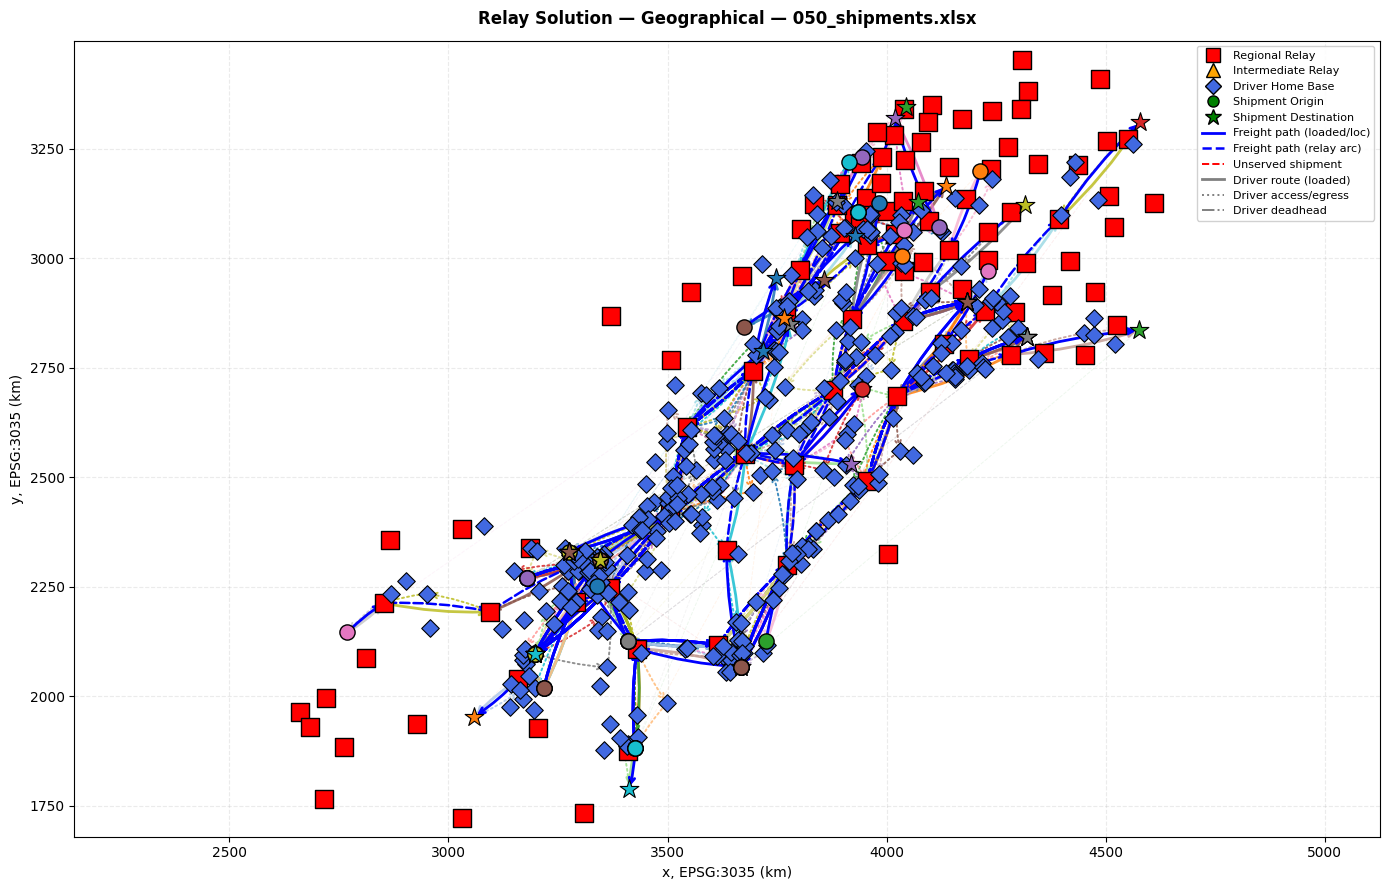

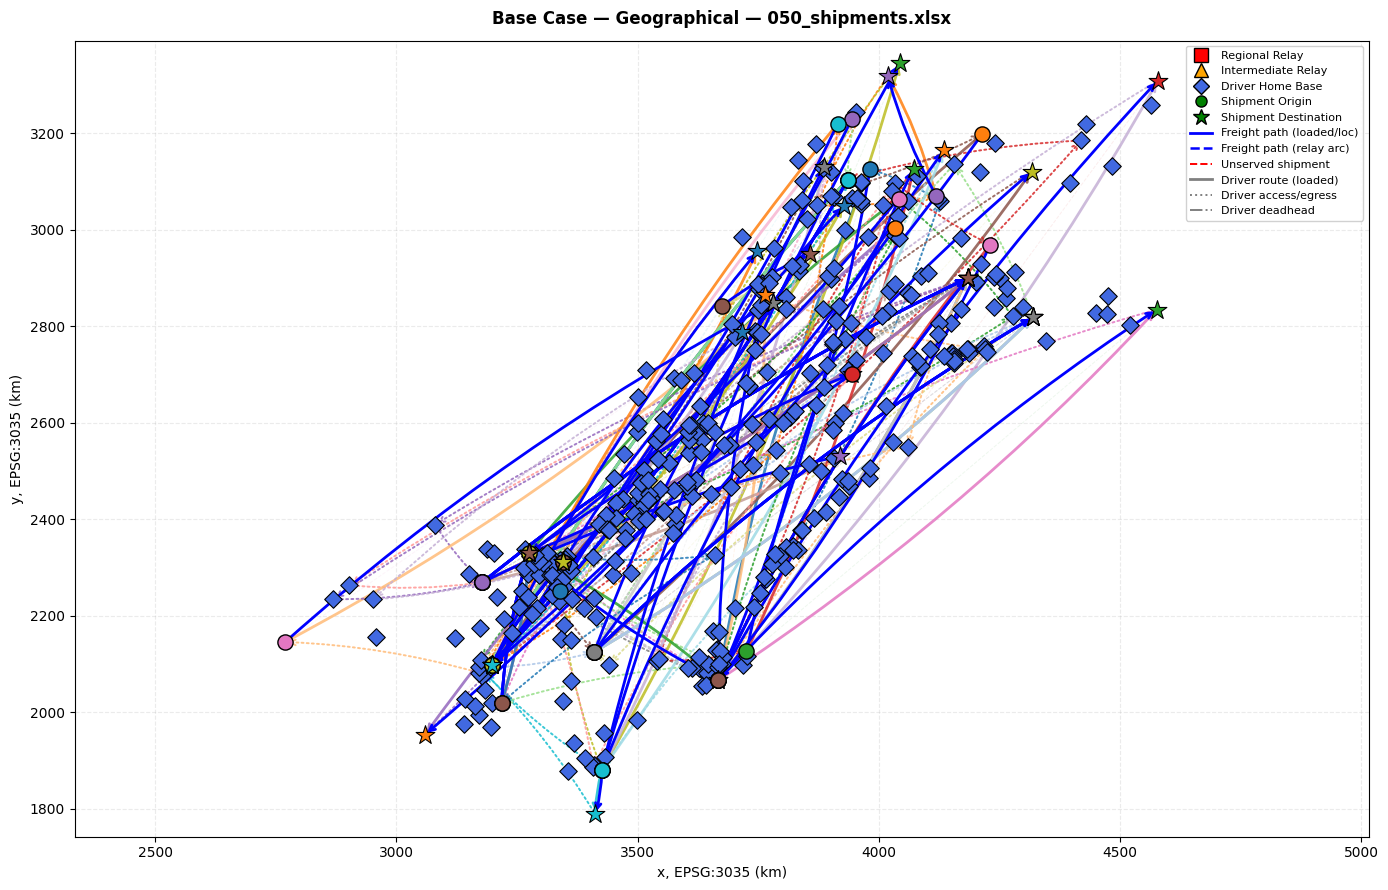

In [ ]:
# Entry point


if __name__ == '__main__':
    INSTANCE_FILE = "G:/Downloads/050_shipments.xlsx"
    iname = INSTANCE_FILE.replace('\\', '/').split('/')[-1]

    # Relay network
    params, relays_df, home_bases_df, shipments_df, distance_matrix_df = \
        load_instance(INSTANCE_FILE)

    # Direct network
    params_d = params
    relays_df_d = relays_df.iloc[0:0]
    home_bases_df_d, shipments_df_d, distance_matrix_df_d = \
        home_bases_df, shipments_df, distance_matrix_df

    print("#"*72)
    print("# CG — Relay + Base Case + Benchmark + Plots")
    print("#"*72)


    # RELAY NETWORK

    print("\n" + "#"*70)
    print("# RELAY NETWORK")
    print("#"*70)
    net_relay = build_network(
        params, relays_df, home_bases_df, shipments_df,
        distance_matrix_df, verbose=True)

    m_relay, vo_relay, hist_relay = solve_column_generation(
        net_relay, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=WS_MAX_RELAY_DEPTH,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    kpi_relay = print_solution(m_relay, vo_relay, net_relay,
                                rest_info=None,
                                instance_name=f'{iname} (relay)')


    # BASE CASE

    print("\n" + "#"*70)
    print("# BASE CASE")
    print("#"*70)
    net_base = build_network_base_case(
        params_d, relays_df_d, home_bases_df_d, shipments_df_d,
        distance_matrix_df_d, verbose=True)

    m_base, vo_base, hist_base = solve_column_generation(
        net_base, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=0,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    rest_info = compute_base_case_rest_cost(vo_base, net_base)
    kpi_base = print_solution(m_base, vo_base, net_base,
                               rest_info=rest_info,
                               instance_name=f'{iname} (base case)')


    # Benchmark comparison

    if kpi_relay is not None and kpi_base is not None:
        print_benchmark(kpi_relay, kpi_base, m_relay, m_base, vo_relay, vo_base)


    # Geographical plots

    fig_r_geo = plot_solution_geographical(
        m_relay, vo_relay, relays_df, home_bases_df, shipments_df,
        title=f'Relay Solution — Geographical — {iname}')

    fig_b_geo = plot_solution_geographical(
        m_base, vo_base, relays_df_d.iloc[0:0],
        home_bases_df_d, shipments_df_d,
        title=f'Base Case — Geographical — {iname}')

    for fig in [fig_r_geo, fig_b_geo]:
        if fig:
            plt.show()

########################################################################
# CG — Relay + Base Case + Benchmark + Plots
########################################################################

######################################################################
# RELAY NETWORK
######################################################################

=== Network (RELAY) ===  |F|=100  |D|=700  |I|=105  T=192
  loc_in:  52390  loc_out: 576076  rel_L: 952911  rel_E:1023020
  direct:    312  trans:  20055  dead_DR: 175491  dead_RO:  47443
  access:1795845  egress:3271963  wait_d:  20160
  A^C=1601744  A^pos=1251040  home-bases=700

=== Building pricing cache ===
  cache build: 50.3s  (bases=700, FW relays=105, composite arcs=952911)

=== Warm-start ===
  Driver-aware construction: 100/100 shipments with matched duties, 486 drivers reserved
  Direct:16F  Relay:300F  Seed:0F  Matched:530D  -> 416F 1986D total
  total: 188.7s -> 416F 1986D cols

=== Column Generation [RELAY] ===
  partial sweep

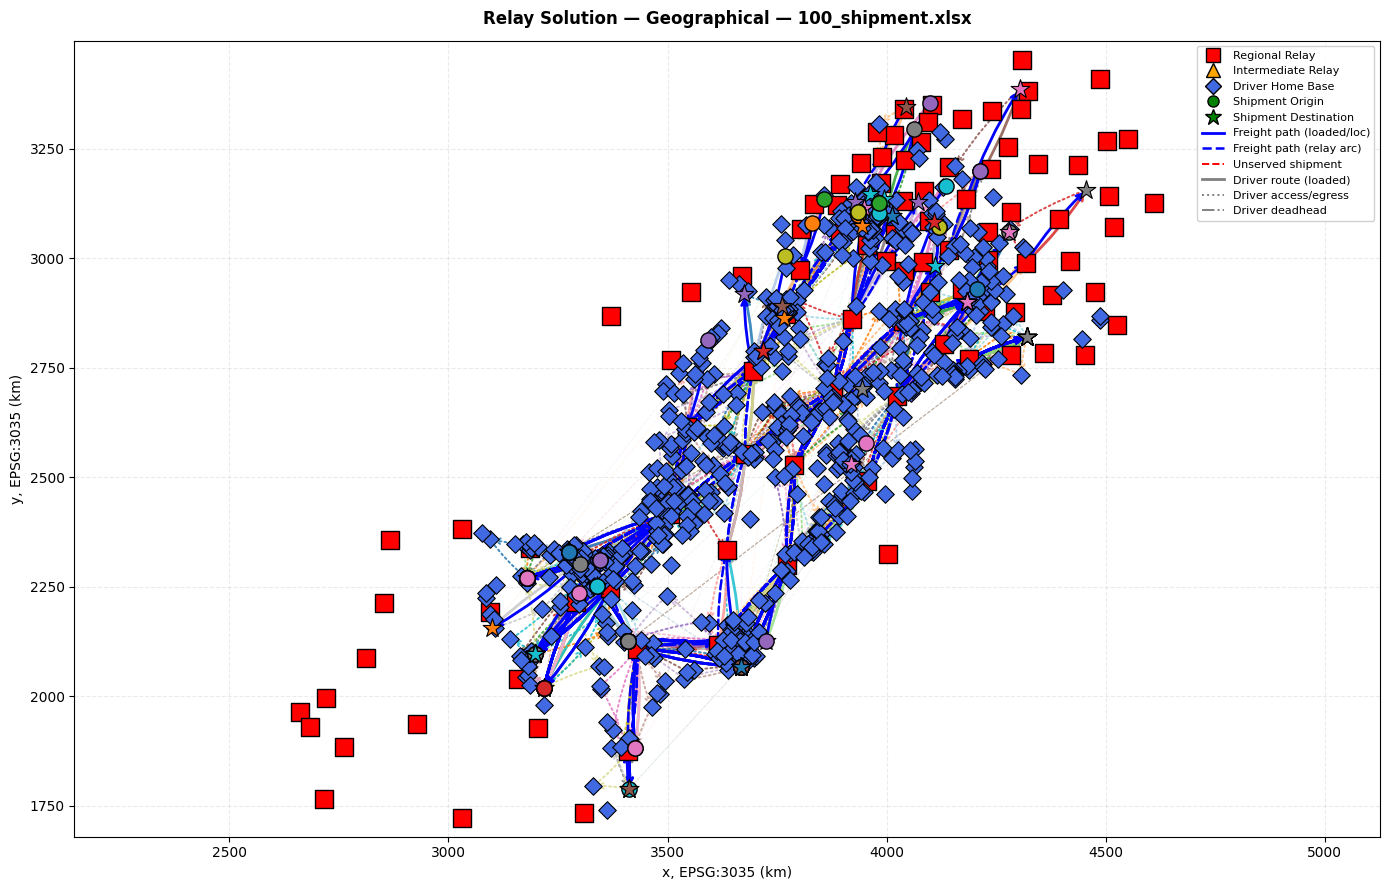

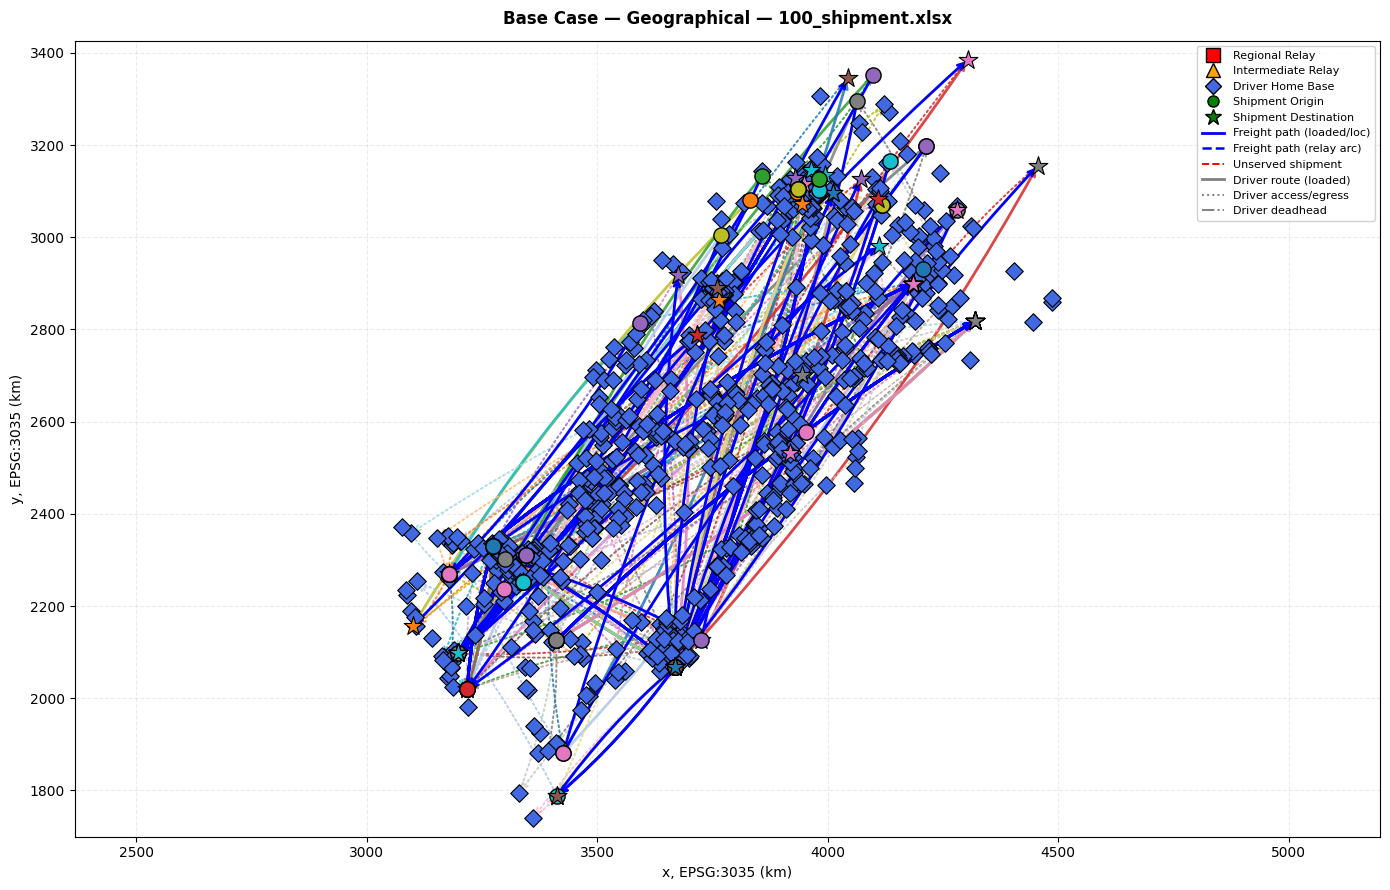

In [ ]:
# Entry point


if __name__ == '__main__':
    INSTANCE_FILE = "G:/Downloads/100_shipment.xlsx"
    iname = INSTANCE_FILE.replace('\\', '/').split('/')[-1]

    # Relay network
    params, relays_df, home_bases_df, shipments_df, distance_matrix_df = \
        load_instance(INSTANCE_FILE)

    # Direct network
    params_d = params
    relays_df_d = relays_df.iloc[0:0]
    home_bases_df_d, shipments_df_d, distance_matrix_df_d = \
        home_bases_df, shipments_df, distance_matrix_df

    print("#"*72)
    print("# CG — Relay + Base Case + Benchmark + Plots")
    print("#"*72)


    # RELAY NETWORK

    print("\n" + "#"*70)
    print("# RELAY NETWORK")
    print("#"*70)
    net_relay = build_network(
        params, relays_df, home_bases_df, shipments_df,
        distance_matrix_df, verbose=True)

    m_relay, vo_relay, hist_relay = solve_column_generation(
        net_relay, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=WS_MAX_RELAY_DEPTH,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    kpi_relay = print_solution(m_relay, vo_relay, net_relay,
                                rest_info=None,
                                instance_name=f'{iname} (relay)')


    # BASE CASE

    print("\n" + "#"*70)
    print("# BASE CASE")
    print("#"*70)
    net_base = build_network_base_case(
        params_d, relays_df_d, home_bases_df_d, shipments_df_d,
        distance_matrix_df_d, verbose=True)

    m_base, vo_base, hist_base = solve_column_generation(
        net_base, verbose=True,
        time_limit_cg=7200.0, time_limit_mip=7200.0, mip_gap=0.0,
        eps_rc=1e-6, top_k=1, top_k_degen=2,
        sweep_full_every=SWEEP_FULL_EVERY,
        freight_sweep_frac=FREIGHT_SWEEP_FRAC,
        driver_sweep_frac=DRIVER_SWEEP_FRAC,
        col_mgmt_every_iters=COL_MGMT_EVERY_ITERS,
        col_mgmt_rc_thresh=COL_MGMT_RC_THRESH,
        col_mgmt_min_keep=COL_MGMT_MIN_KEEP,
        sigma=DUAL_COMPLETION_SIGMA, match_wait_flex=MATCH_WAIT_FLEX,
        ship_stall_streak=SHIP_STALL_STREAK,
        ship_cooldown_iters=SHIP_COOLDOWN_ITERS, pool_cap=POOL_CAP,
        ws_relay_depth=0,
        ws_paths_per_ship=WS_MAX_PATHS_PER_SHIP,
        max_match_per_seg=MAX_MATCH_PER_SEGMENT,
        stabilize=STABILIZE, smooth_beta=SMOOTH_BETA,
        driver_full_stride=DRIVER_FULL_STRIDE, full_stall_limit=FULL_STALL_LIMIT,
    )
    rest_info = compute_base_case_rest_cost(vo_base, net_base)
    kpi_base = print_solution(m_base, vo_base, net_base,
                               rest_info=rest_info,
                               instance_name=f'{iname} (base case)')


    # Benchmark comparison

    if kpi_relay is not None and kpi_base is not None:
        print_benchmark(kpi_relay, kpi_base, m_relay, m_base, vo_relay, vo_base)


    # Geographical plots

    fig_r_geo = plot_solution_geographical(
        m_relay, vo_relay, relays_df, home_bases_df, shipments_df,
        title=f'Relay Solution — Geographical — {iname}')

    fig_b_geo = plot_solution_geographical(
        m_base, vo_base, relays_df_d.iloc[0:0],
        home_bases_df_d, shipments_df_d,
        title=f'Base Case — Geographical — {iname}')

    for fig in [fig_r_geo, fig_b_geo]:
        if fig:
            plt.show()